<a href="https://www.kaggle.com/code/jueyetao/grey-box-model-forcasting?scriptVersionId=365929353" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# From raw signals to 30-minute forecasts
### An Avedøre wastewater treatment case study

This notebook combines three analyses of **Line 3, Tank 1**. It audits the two-year monitoring record, builds practical N₂O forecast baselines, and evaluates NH₄ and N₂O grey-box dynamics under a chronological protocol.

| Section | Question |
|---|---|
| [1. Data quality](#1.-Data-quality-and-time-alignment) | Which signals can be trusted, and where is data missing? |
| [2. Baseline forecasts](#2.-Thirty-minute-N₂O-baselines) | How difficult is it to beat the last observed value? |
| [3. Paper-based dynamics](#3.-Grey-box-dynamics-from-Equations-4-and-5) | What do delayed process inputs add for NH₄ and N₂O? |
| [4. Rolling evaluation](#4.-Walk-forward-N₂O-evaluation) | Does daily refitting improve a fixed grey-box model? |

**Run on Kaggle.** Import this notebook, attach the dataset containing `aved_raw.csv` or `aved_raw_semicolon.csv`, and run all cells on CPU. One raw file is sufficient. The supplied notebook also contains a completed local run and 16 figures. To run elsewhere, set `INPUT_PATH` in the next cell or set the `WASTEWATER_INPUT_PATH` environment variable.

**Provenance.** The original preprocessing and the project outputs recorded in the discussion inform this consolidation. The baseline implementation below declares a reproducible feature set and reports the historical baseline scores separately. The grey-box comparison uses the previously frozen N₂O static template and refits the rolling parameters from the raw data. Forecast targets are measured tank concentrations.

**Sources.** [Avedøre dataset, Mendeley Data v4, CC BY 4.0](https://data.mendeley.com/datasets/xmbxhscgpr/4) · [Dataset documentation and quality codes](https://arxiv.org/html/2407.05959v1) · [Debel et al., 2025, grey-box equations and MPC](https://doi.org/10.1016/j.jwpe.2025.108128)

In [1]:
from pathlib import Path
import hashlib
import json
import os

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.optimize import brentq, least_squares
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

INPUT_PATH = os.environ.get("WASTEWATER_INPUT_PATH")
KAGGLE_INPUT = Path("/kaggle/input")
OUTPUT_DIR = Path(os.environ.get(
    "WASTEWATER_OUTPUT_DIR",
    "/kaggle/working/wastewater_forecast_atlas" if KAGGLE_INPUT.is_dir()
    else "wastewater_forecast_atlas_outputs",
))
STEP = pd.Timedelta(minutes=2)
HORIZON = 15
VALIDATION_START = pd.Timestamp("2023-10-01", tz="UTC")
TEST_START = pd.Timestamp("2024-01-01", tz="UTC")
SPLITS = ["Train", "Validation", "Test"]
GRID = dict(rule="2min", closed="right", label="right", origin="start_day")

INK, MUTED, TEAL, GOLD, RUST, BLUE = (
    "#152B3C", "#56697C", "#008478", "#B87812", "#A94338", "#32679A"
)
COLORS = {
    "Persistence": "#788A9B", "Ridge": RUST, "Rolling mean · 10 min": "#89AEB0",
    "Rolling mean · 30 min": "#6291AA", "Rolling mean · 60 min": BLUE,
    "Static grey-box": TEAL, "Rolling · 7 days": BLUE, "Rolling · 3 days": GOLD,
}
plt.rcParams.update({
    "figure.dpi": 125, "savefig.dpi": 160, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": "#CED7DE",
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": "#DCE5EB",
    "legend.frameon": False, "figure.constrained_layout.use": True,
})
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

def show_figure(fig, name):
    fig.savefig(FIGURE_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

def scores(predictions, observed):
    error = predictions.sub(observed, axis=0)
    assert len(error) > 0 and np.isfinite(error.to_numpy()).all()
    result = pd.DataFrame({
        "n": len(error), "MAE": error.abs().mean(),
        "RMSE": error.pow(2).mean().pow(0.5), "mean_error": error.mean(),
    })
    for metric in ("MAE", "RMSE"):
        reference = result.at["Persistence", metric]
        result[f"{metric}_improvement_pct"] = (
            100 * (1 - result[metric] / reference) if reference else np.nan
        )
    return result.rename_axis("model")

def split_for(horizon):
    origin = grid_index.to_series()
    target = origin.shift(-horizon)
    return pd.Series(np.select([
        origin.lt(VALIDATION_START) & target.lt(VALIDATION_START),
        origin.ge(VALIDATION_START) & origin.lt(TEST_START) & target.lt(TEST_START),
        origin.ge(TEST_START) & target.notna(),
    ], SPLITS, default="Excluded"), index=grid_index, name="split")

def monthly_scores(predictions, observed, rolling_used=None):
    months = predictions.index.strftime("%Y-%m")
    rows = []
    for month, batch in predictions.groupby(months, sort=True):
        table = scores(batch, observed.loc[batch.index])
        if rolling_used is not None:
            table["fallback_pct"] = 100 * (~rolling_used.loc[batch.index]).mean()
        rows.append(table.assign(month_utc=month).reset_index())
    return pd.concat(rows, ignore_index=True).set_index(["month_utc", "model"])

def plot_score_bars(ax, table, metric, title):
    models = list(table.index)
    bars = ax.barh(models[::-1], table[metric].iloc[::-1],
                   color=[COLORS.get(name, TEAL) for name in models[::-1]])
    ax.bar_label(bars, fmt="%.4f", padding=4, fontsize=9)
    ax.set_xlim(0, table[metric].max() * 1.24)
    ax.set_title(title, loc="left")
    ax.set_xlabel(f"{metric} (mg N/L)")
    ax.grid(axis="x", alpha=0.75)
    ax.set_axisbelow(True)

## 1. Data quality and time alignment

Each of the 24 signals has a `value` column and a matching `quality` column. The two published CSV variants differ in delimiter. Use one. The dataset uses **quality 0 for good** and **quality 1 for bad**. A quality mask removes individual measurements from the modeling view and preserves the underlying timeline.

The two-minute grid uses right-closed windows $(t-2\,\mathrm{min},t]$. For each signal, retain the last finite quality-0 observation in the window and record its age and the number of usable observations. The original 24-signal dictionary stays available for auditing. [Dataset definitions and codes](https://arxiv.org/html/2407.05959v1#S2.SS2)

In [2]:
if INPUT_PATH:
    source_path = Path(INPUT_PATH)
else:
    root = KAGGLE_INPUT if KAGGLE_INPUT.is_dir() else Path.cwd()
    candidates = sorted(root.rglob("aved_raw.csv")) or sorted(
        root.rglob("aved_raw_semicolon.csv")
    )
    if len(candidates) != 1:
        raise ValueError(f"Set INPUT_PATH to one raw CSV. Found {len(candidates)} candidates.")
    source_path = candidates[0]

with source_path.open(encoding="utf-8-sig") as stream:
    header = stream.readline()
delimiter = ";" if header.count(";") > header.count(",") else ","
raw = pd.read_csv(source_path, sep=delimiter)
raw_shape = raw.shape
clock = pd.to_datetime(raw.pop("time"), utc=True, errors="raise")
assert clock.notna().all() and clock.is_unique, "Missing or duplicate timestamps."
originally_sorted = clock.is_monotonic_increasing
raw.index = pd.DatetimeIndex(clock, name="time")
raw.sort_index(inplace=True)
intervals = raw.index.to_series().diff().dt.total_seconds().value_counts().sort_index()
value_tags = {column.removesuffix(" value") for column in raw if column.endswith(" value")}
quality_tags = {column.removesuffix(" quality") for column in raw if column.endswith(" quality")}
assert value_tags == quality_tags and value_tags, "Unpaired value or quality tags."
with source_path.open("rb") as stream:
    digest = hashlib.sha256()
    for block in iter(lambda: stream.read(2**20), b""):
        digest.update(block)
source_sha256 = digest.hexdigest()

display(pd.Series({
    "source_file": source_path.name, "delimiter": repr(delimiter),
    "raw_rows": raw_shape[0], "raw_columns": raw_shape[1],
    "signals": len(value_tags), "originally_sorted": originally_sorted,
    "first_utc": raw.index.min(), "last_utc": raw.index.max(),
    "longest_raw_row_interval_min": intervals.index.max() / 60,
    "sha256": source_sha256,
}, name="value").to_frame())
display(intervals.rename("raw_intervals").rename_axis("seconds").to_frame())

,value
source_file,aved_raw.csv
delimiter,"','"
raw_rows,906815
raw_columns,49
signals,24
originally_sorted,True
first_utc,2022-06-11 22:01:00+00:00
last_utc,2024-06-11 21:59:00+00:00
longest_raw_row_interval_min,20.0
sha256,b57bc042a394d84da9fc9620aae5b90f029885dbafa14d...


,raw_intervals
seconds,
60.0,761026
120.0,145776
180.0,5
240.0,5
300.0,1
1200.0,1


In [3]:
# Raw tag, short label, engineering meaning, unit and role.
SIGNALS = [
    ("BIOLOGY.BLOWERSTATION 1.Q.AIRFLOW", "Blower airflow", "Blower station 1 total airflow", "Nm³/h", "Measurement"),
    ("BIOLOGY.LINE 3 TANK 1 VALVE 1.PCT", "T1 valve", "Tank 1 valve position", "%", "Control"),
    ("BIOLOGY.LINE 3 TANK 1.N2O", "N2O", "Tank 1 dissolved nitrous oxide as nitrogen", "mg N/L", "Measurement"),
    ("BIOLOGY.LINE 3 TANK 1.NH4", "NH4", "Tank 1 ammonium as nitrogen", "mg N/L", "Measurement"),
    ("BIOLOGY.LINE 3 TANK 1.NO3", "T1 nitrate", "Tank 1 nitrate as nitrogen", "mg N/L", "Measurement"),
    ("BIOLOGY.LINE 3 TANK 1.O2", "T1 oxygen", "Tank 1 dissolved oxygen", "mg/L", "Measurement"),
    ("BIOLOGY.LINE 3 TANK 1.O2.SETPOINT", "T1 oxygen setpoint", "Tank 1 dissolved oxygen setpoint", "mg/L inferred", "Setpoint"),
    ("BIOLOGY.LINE 3 TANK 1.PROCESSPHASE", "process_phase", "Tank 1 biological phase", "code", "State"),
    ("BIOLOGY.LINE 3 TANK 1.Q.AIRFLOW", "airflow", "Tank 1 estimated airflow", "Nm³/h", "Estimate"),
    ("BIOLOGY.LINE 3 TANK 1.SS", "T1 suspended solids", "Tank 1 suspended solids", "g/L", "Measurement"),
    ("BIOLOGY.LINE 3 TANK 1.TEMPERATURE", "T1 temperature", "Tank 1 temperature", "°C", "Measurement"),
    ("BIOLOGY.LINE 3 TANK 2 VALVE 1.PCT", "T2 valve", "Tank 2 valve position", "%", "Control"),
    ("BIOLOGY.LINE 3 TANK 2.O2", "T2 oxygen", "Tank 2 dissolved oxygen", "mg/L", "Measurement"),
    ("BIOLOGY.LINE 3 TANK 2.O2.SETPOINT", "T2 oxygen setpoint", "Tank 2 dissolved oxygen setpoint", "mg/L inferred", "Setpoint"),
    ("BIOLOGY.LINE 3 TANK 2.PROCESSPHASE", "T2 phase", "Tank 2 biological phase", "code", "State"),
    ("BIOLOGY.LINE 3 TANK 2.Q.AIRFLOW", "T2 airflow", "Tank 2 estimated airflow", "Nm³/h", "Estimate"),
    ("BIOLOGY.LINE 3 TANK 2.SS", "T2 suspended solids", "Tank 2 suspended solids", "g/L", "Measurement"),
    ("BIOLOGY.LINE 3 TANK 2.TEMPERATURE", "T2 temperature", "Tank 2 temperature", "°C", "Measurement"),
    ("BIOLOGY.LINE 3.PHASECODE.SETPOINT", "Line phase setpoint", "Four-digit line phase setpoint", "code", "Setpoint"),
    ("BIOLOGY.LINE 3.PROCESSPHASE.INLET TANK", "inlet_tank", "Line 3 receiving tank", "code", "State"),
    ("BIOLOGY.LINE 3.PROCESSPHASE.OUTLET TANK", "Outlet tank", "Line 3 discharging tank", "code", "State"),
    ("BIOLOGY.LINE 3 TANK 1.PO4", "T1 phosphate", "Tank 1 phosphate as phosphorus", "mg P/L", "Measurement"),
    ("INLET.Q", "Plant inlet flow", "Total plant influent flow", "m³/h", "Measurement"),
    ("INLET.STATE.SWM INLET FLOW", "Stormwater mode", "High-flow operating mode", "code", "State"),
]
dictionary = pd.DataFrame(
    SIGNALS, columns=["raw_tag", "signal", "definition", "unit", "role"]
).set_index("signal")
dictionary["value_column"] = dictionary["raw_tag"] + " value"
dictionary["quality_column"] = dictionary["raw_tag"] + " quality"
assert set(dictionary["raw_tag"]) == value_tags
MODELING_SIGNALS = ["N2O", "NH4", "airflow", "process_phase", "inlet_tank"]
display(dictionary.loc[MODELING_SIGNALS, ["definition", "unit", "role"]])

bins = pd.Series(1, index=raw.index).resample(**GRID).size()
grid_index = bins.index
grid_clock = grid_index.to_series()
source_clock = raw.index.to_series()
aligned_columns, alignment_columns, audit_rows = {}, {}, []

for signal, spec in dictionary.iterrows():
    value = raw[spec["value_column"]]
    quality = raw[spec["quality_column"]]
    present = value.notna()
    good_code = quality.eq(0)
    good = present & good_code & np.isfinite(value)
    bad = present & quality.eq(1)
    unknown = present & ~quality.isin([0, 1])
    nonfinite_good = present & good_code & ~np.isfinite(value)
    retained = value.where(good).resample(**GRID).last()
    aligned_columns[signal] = retained
    valid_count = good.resample(**GRID).sum()
    latest = source_clock.where(good).resample(**GRID).last()
    alignment_columns[f"{signal}__valid_count"] = valid_count.astype("int16")
    alignment_columns[f"{signal}__bad_quality_count"] = bad.resample(**GRID).sum().astype("int16")
    alignment_columns[f"{signal}__unknown_quality_count"] = unknown.resample(**GRID).sum().astype("int16")
    alignment_columns[f"{signal}__source_age_seconds"] = (grid_clock - latest).dt.total_seconds()
    audit_rows.append({
        "signal": signal, "raw_observed": int(present.sum()),
        "raw_missing": int((~present).sum()), "bad_quality": int(bad.sum()),
        "unknown_quality": int(unknown.sum()), "nonfinite_quality_0": int(nonfinite_good.sum()),
        "usable_raw": int(good.sum()), "presence_mismatch": int(present.ne(quality.notna()).sum()),
        "usable_bins": int(retained.notna().sum()),
        "raw_observed_bins": int(present.resample(**GRID).max().eq(True).sum()),
        "bins_with_multiple_usable_values": int(valid_count.gt(1).sum()),
    })

aligned = pd.DataFrame(aligned_columns, index=grid_index)
alignment_metadata = pd.DataFrame(alignment_columns, index=grid_index)
audit = pd.DataFrame(audit_rows).set_index("signal")
audit["usable_grid_pct"] = 100 * audit["usable_bins"] / len(aligned)
assert audit[["raw_missing", "bad_quality", "unknown_quality",
              "nonfinite_quality_0", "usable_raw"]].sum(axis=1).eq(len(raw)).all()
ages = alignment_metadata.filter(like="__source_age_seconds")
assert not (ages.lt(0) | ages.ge(STEP.total_seconds())).any().any()
assert grid_index.to_series().diff().dropna().eq(STEP).all()

data = aligned[MODELING_SIGNALS].copy()
print(f"Regular grid  •  {len(data):,} bins  •  {data.index[0]} to {data.index[-1]}")
display(audit.loc[MODELING_SIGNALS].round(2))

Regular grid  •  526,320 bins  •  2022-06-11 22:02:00+00:00 to 2024-06-11 22:00:00+00:00


,definition,unit,role
signal,,,
N2O,Tank 1 dissolved nitrous oxide as nitrogen,mg N/L,Measurement
NH4,Tank 1 ammonium as nitrogen,mg N/L,Measurement
airflow,Tank 1 estimated airflow,Nm³/h,Estimate
process_phase,Tank 1 biological phase,code,State
inlet_tank,Line 3 receiving tank,code,State


,raw_observed,raw_missing,bad_quality,unknown_quality,nonfinite_quality_0,usable_raw,presence_mismatch,usable_bins,raw_observed_bins,bins_with_multiple_usable_values,usable_grid_pct
signal,,,,,,,,,,,
N2O,520546,386269,67732,0,0,452814,0,451086,518461,1728,85.71
NH4,520595,386220,54988,0,0,465607,0,464147,518174,1460,88.19
airflow,470203,436612,5676,0,0,464527,0,464397,470057,130,88.23
process_phase,519349,387466,0,0,0,519349,0,516978,516978,2371,98.23
inlet_tank,526285,380530,0,0,0,526285,0,526285,526285,0,99.99


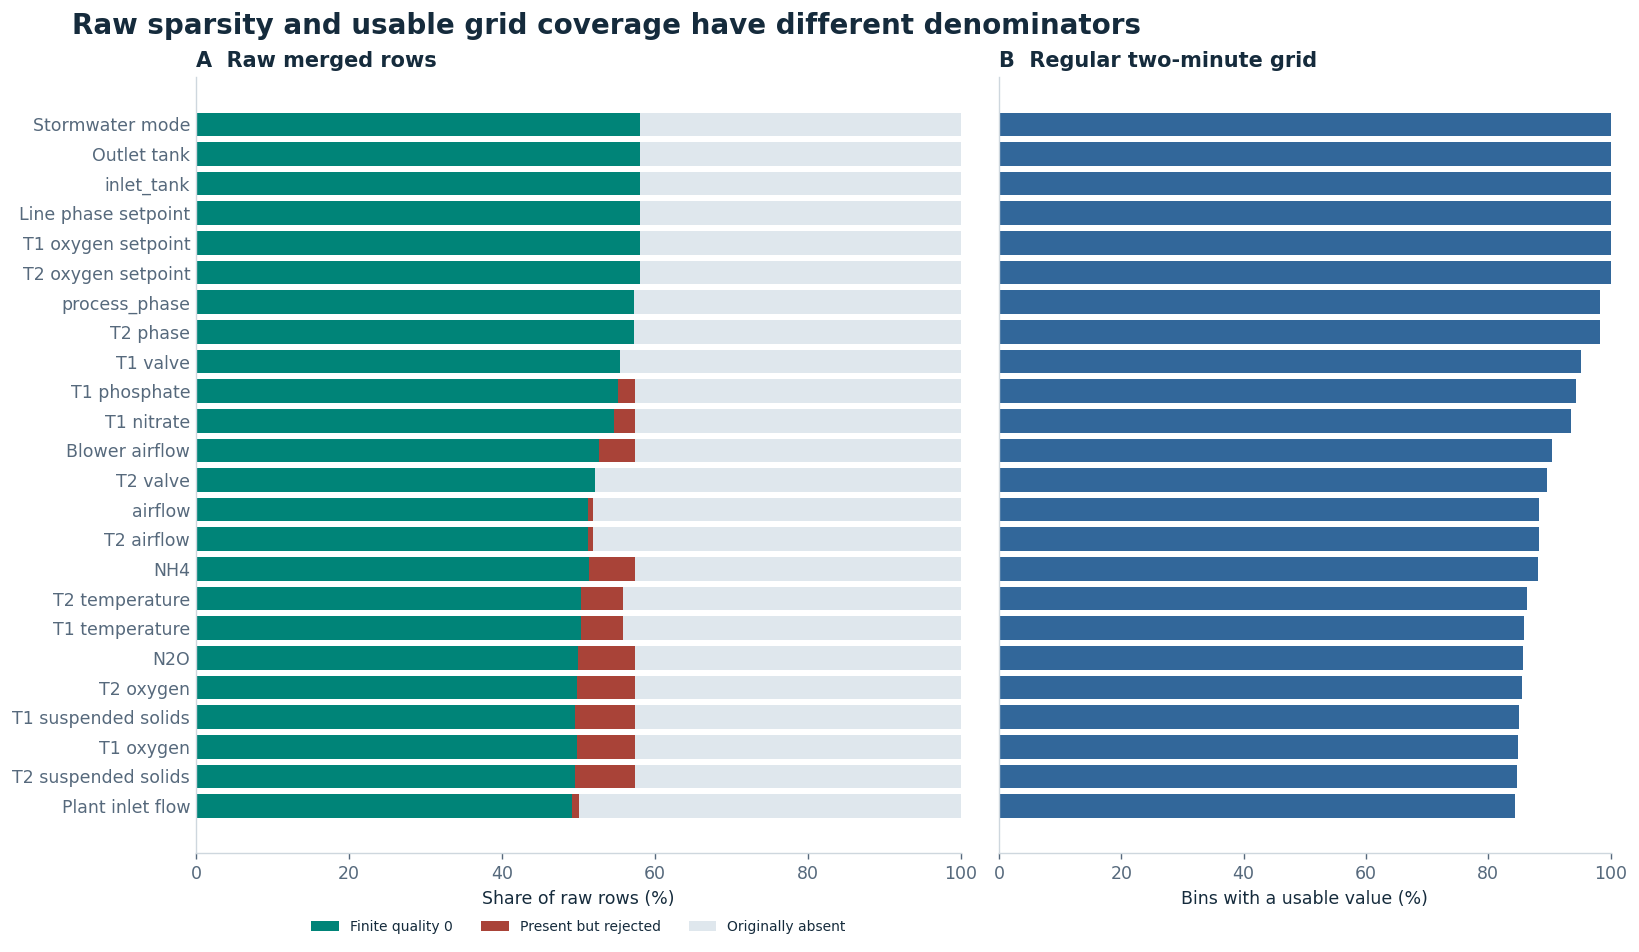

In [4]:
# Compare denominators before and after regularization.
order = audit["usable_grid_pct"].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(13, 7.5), sharey=True,
                         gridspec_kw={"width_ratios": [1.25, 1]})
axes[0].barh(order, audit.loc[order, "usable_raw"] / len(raw) * 100,
             color=TEAL, label="Finite quality 0")
left = audit.loc[order, "usable_raw"].to_numpy() / len(raw) * 100
rejected = (audit.loc[order, "raw_observed"] - audit.loc[order, "usable_raw"]).to_numpy() / len(raw) * 100
axes[0].barh(order, rejected, left=left, color=RUST, label="Present but rejected")
axes[0].barh(order, 100-left-rejected, left=left+rejected,
             color="#DFE7ED", label="Originally absent")
axes[1].barh(order, audit.loc[order, "usable_grid_pct"], color=BLUE)
for ax, title, xlabel in zip(
    axes, ["A  Raw merged rows", "B  Regular two-minute grid"],
    ["Share of raw rows (%)", "Bins with a usable value (%)"],
):
    ax.set(xlim=(0, 100), xlabel=xlabel)
    ax.set_title(title, loc="left")
    ax.tick_params(axis="y", length=0)
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3, fontsize=8)
fig.suptitle("Raw sparsity and usable grid coverage have different denominators",
             x=0.04, ha="left", fontweight="bold", fontsize=16)
show_figure(fig, "01_quality_and_coverage")

### Coverage, gap length and sensor behavior

Several signals share timestamps in the raw export, so row-level sparsity overstates missingness on the modeling grid. The grid still contains long interruptions. Compare missing bins with the source records to distinguish absence from a run of bad quality. Negative readings, repeated minima and airflow/phase disagreements remain visible as diagnostic flags.

Phase 0 is anaerobic, 1 is anoxic denitrification, and 2 is aerobic nitrification. An inlet-tank code of 0 is outside the documented 1/2 mapping. The N₂O grey-box evaluation below uses phases 1 and 2. [Phase definitions](https://arxiv.org/html/2407.05959v1#S2.SS2.SSS4)

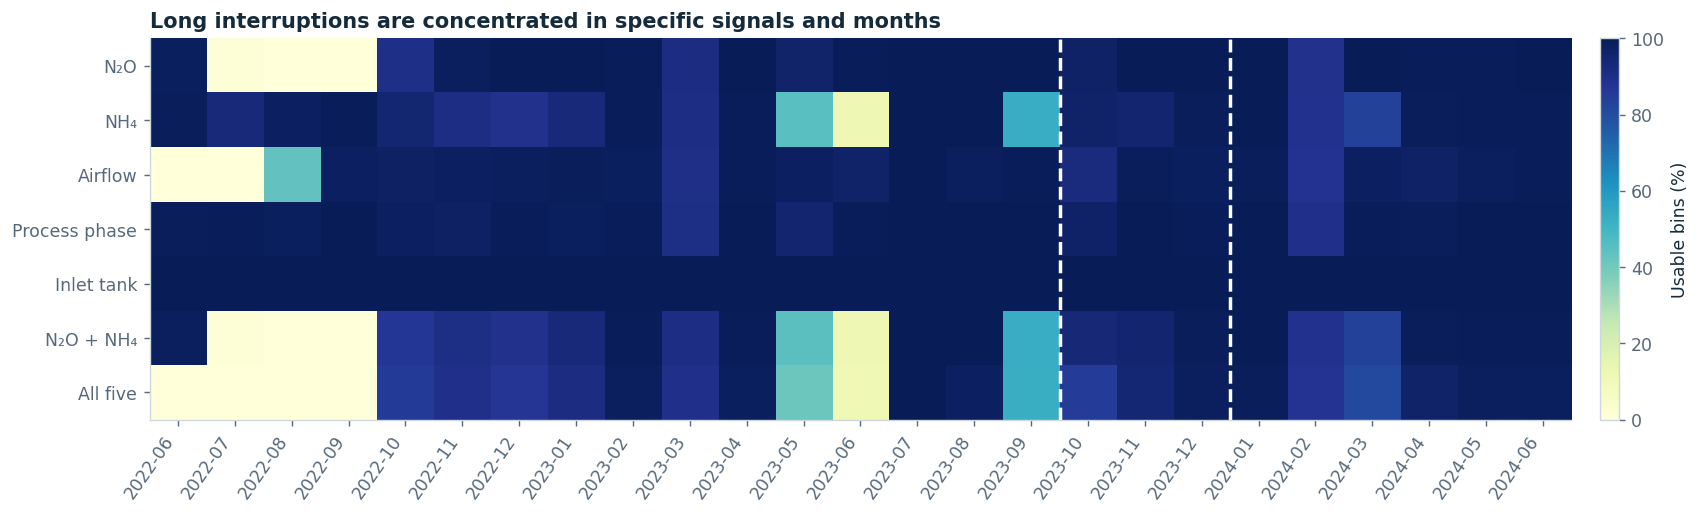

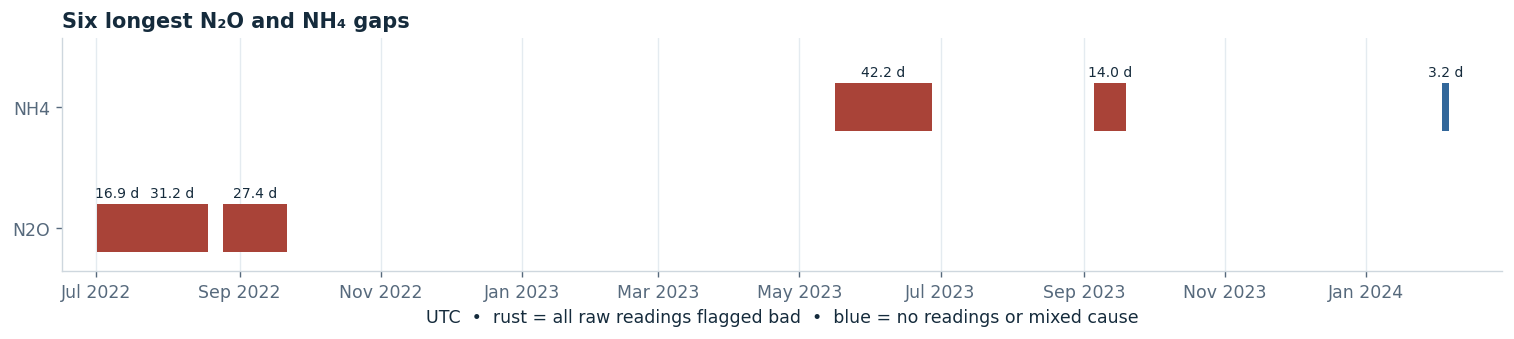

,signal,first_bin,last_bin,duration_days,raw_observed,bad_quality,gap_source
0,N2O,2022-07-01 08:40:00+00:00,2022-07-18 06:08:00+00:00,16.90,12154,12154,All raw readings flagged bad
1,N2O,2022-07-18 06:16:00+00:00,2022-08-18 10:24:00+00:00,31.17,22399,22399,All raw readings flagged bad
2,N2O,2022-08-24 21:18:00+00:00,2022-09-21 07:08:00+00:00,27.41,19726,19726,All raw readings flagged bad
3,NH4,2023-05-16 06:08:00+00:00,2023-06-27 11:30:00+00:00,42.22,30376,30376,All raw readings flagged bad
4,NH4,2023-09-05 06:00:00+00:00,2023-09-19 05:40:00+00:00,13.99,10065,10065,All raw readings flagged bad
5,NH4,2024-02-02 15:16:00+00:00,2024-02-05 18:52:00+00:00,3.15,0,0,No raw readings


,gap_count,longest_gap_hours,median_gap_min
Plant inlet flow,4371,2220.23,2.0
airflow,4727,1597.73,2.0
T2 airflow,4727,1597.73,2.0
T2 valve,1572,1575.00,2.0
T1 temperature,4206,1127.43,2.0
NH4,3564,1013.40,2.0
T2 temperature,1908,748.30,2.0
N2O,1995,748.17,2.0


In [5]:
def missing_runs(series):
    missing = series.isna()
    runs = missing.ne(missing.shift(fill_value=False)).cumsum()
    observed_clock = series.index.to_series()
    return observed_clock[missing].groupby(runs[missing]).agg(
        first_bin="min", last_bin="max", missing_bins="size"
    ).assign(signal=series.name)

gap_runs = pd.concat([missing_runs(aligned[name]) for name in aligned], ignore_index=True)
gap_runs["duration_hours"] = gap_runs["missing_bins"] / 30
gap_summary = gap_runs.groupby("signal")["duration_hours"].agg(
    gap_count="size", longest_gap_hours="max", median_gap_hours="median"
).reindex(aligned.columns)
gap_summary["median_gap_min"] = 60 * gap_summary.pop("median_gap_hours")

major_gaps = (
    gap_runs[gap_runs["signal"].isin(["N2O", "NH4"])]
    .sort_values("duration_hours", ascending=False).groupby("signal").head(3)
    .sort_values(["signal", "first_bin"]).reset_index(drop=True)
)
gap_causes = []
for row in major_gaps.itertuples():
    source = raw.loc[(raw.index > row.first_bin - STEP) & (raw.index <= row.last_bin)]
    spec = dictionary.loc[row.signal]
    present = source[spec["value_column"]].notna()
    quality = source[spec["quality_column"]]
    gap_causes.append({
        "raw_observed": int(present.sum()),
        "bad_quality": int((present & quality.eq(1)).sum()),
        "unknown_quality": int((present & ~quality.isin([0, 1])).sum()),
    })
major_gaps = major_gaps.join(pd.DataFrame(gap_causes))
major_gaps["duration_days"] = major_gaps["duration_hours"] / 24
major_gaps["gap_source"] = np.select(
    [major_gaps["raw_observed"].eq(0), major_gaps["bad_quality"].eq(major_gaps["raw_observed"])],
    ["No raw readings", "All raw readings flagged bad"], default="Mixed",
)
coverage_flags = data.notna()
coverage_flags["N₂O + NH₄"] = coverage_flags[["N2O", "NH4"]].all(axis=1)
coverage_flags["All five"] = coverage_flags[MODELING_SIGNALS].all(axis=1)
month_keys = grid_index.strftime("%Y-%m")
coverage = 100 * coverage_flags.groupby(month_keys).mean()

fig, ax = plt.subplots(figsize=(13.5, 4))
heat = ax.imshow(coverage.T, aspect="auto", cmap="YlGnBu", vmin=0, vmax=100)
ax.set_xticks(np.arange(len(coverage)), coverage.index, rotation=55, ha="right")
ax.set_yticks(np.arange(len(coverage.columns)),
              ["N₂O", "NH₄", "Airflow", "Process phase", "Inlet tank", "N₂O + NH₄", "All five"])
for boundary in (VALIDATION_START, TEST_START):
    ax.axvline(coverage.index.get_loc(boundary.strftime("%Y-%m")) - 0.5,
               color="white", lw=2, ls="--")
fig.colorbar(heat, ax=ax, label="Usable bins (%)", pad=0.02)
ax.set_title("Long interruptions are concentrated in specific signals and months", loc="left")
show_figure(fig, "02_monthly_coverage")

fig, ax = plt.subplots(figsize=(12, 2.6))
for row in major_gaps.itertuples():
    color = RUST if row.gap_source == "All raw readings flagged bad" else BLUE
    ax.barh(row.signal, row.last_bin - row.first_bin + STEP,
            left=row.first_bin-STEP, height=0.40, color=color)
    middle = row.first_bin + (row.last_bin - row.first_bin) / 2
    ax.annotate(f"{row.duration_days:.1f} d", (middle, row.signal),
                xytext=(0, 16), textcoords="offset points", ha="center",
                va="bottom", fontsize=8, color=INK)
ax.set_xlim(major_gaps["first_bin"].min() - pd.Timedelta(days=15),
            major_gaps["last_bin"].max() + pd.Timedelta(days=23))
ax.set_ylim(-.36, 1.57)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Six longest N₂O and NH₄ gaps", loc="left")
ax.set_xlabel("UTC  •  rust = all raw readings flagged bad  •  blue = no readings or mixed cause")
ax.grid(axis="x", alpha=0.75)
ax.set_axisbelow(True)
show_figure(fig, "03_long_gap_timeline")
display(major_gaps[["signal", "first_bin", "last_bin", "duration_days",
                    "raw_observed", "bad_quality", "gap_source"]].round({"duration_days": 2}))
display(gap_summary.nlargest(8, "longest_gap_hours").round(2))

N₂O minimum -0.02372685 occurs in 77,831 usable bins.


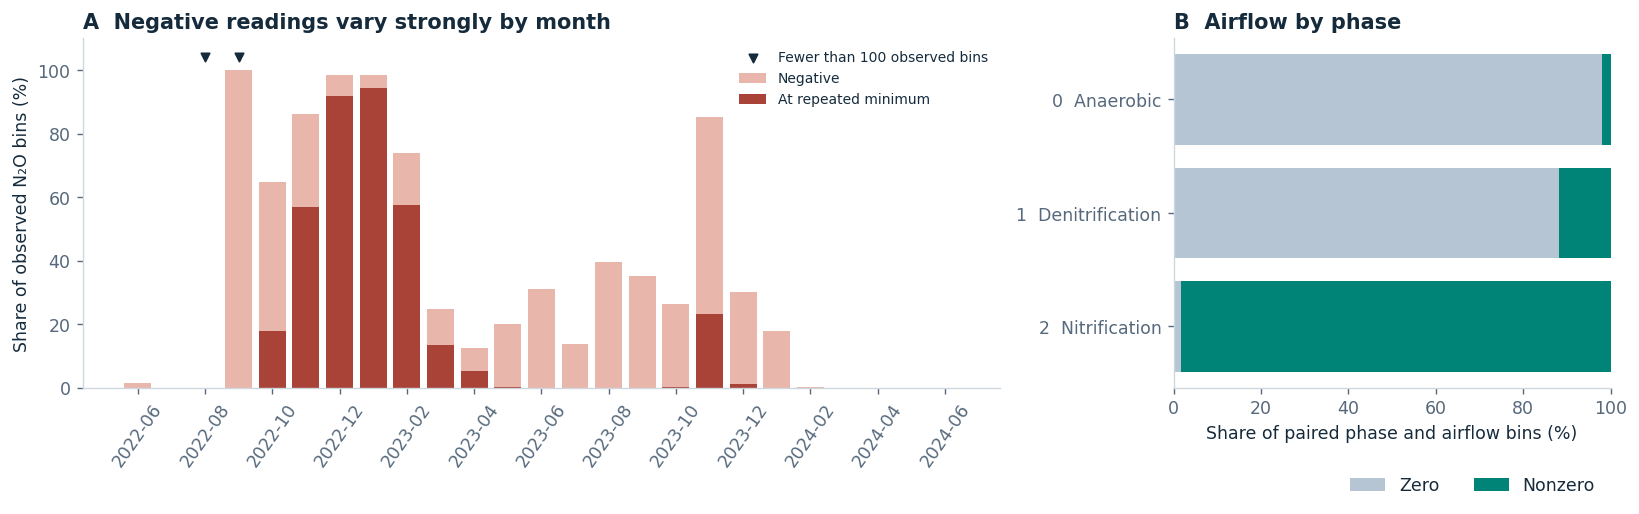

,count,min,1%,50%,99%,max,negative_count,zero_count
N2O,451086.0,-0.02373,-0.02373,0.01100,1.10301,12.00000,163164,7842
NH4,464147.0,-0.00451,0.10771,1.99758,8.09720,20.00380,30,16
airflow,464397.0,0.00000,0.00000,2138.52484,6368.28255,12973.04718,0,192661


col_0,Nonzero,Zero
process_phase,,
0,437,21945
1,22162,165517
2,247533,3982


In [6]:
n2o_min = data["N2O"].min()
flags = pd.DataFrame({
    "N2O_negative": data["N2O"].lt(0),
    "N2O_at_observed_minimum": data["N2O"].eq(n2o_min),
    "NH4_negative": data["NH4"].lt(0),
    "airflow_zero": data["airflow"].eq(0),
    "inlet_tank_outside_documented_codes": (
        data["inlet_tank"].notna() & ~data["inlet_tank"].isin([1, 2])
    ),
})
paired_air = data.dropna(subset=["airflow", "process_phase"])
air_phase = pd.crosstab(paired_air["process_phase"].astype(int),
                        np.where(paired_air["airflow"].eq(0), "Zero", "Nonzero"))
air_phase_pct = air_phase.div(air_phase.sum(axis=1), axis=0) * 100
monthly_n2o = data["N2O"].groupby(month_keys).agg(["count", "median"])
monthly_n2o["negative_pct"] = (
    100 * flags["N2O_negative"].groupby(month_keys).sum() / monthly_n2o["count"]
)
monthly_n2o["minimum_pct"] = (
    100 * flags["N2O_at_observed_minimum"].groupby(month_keys).sum() / monthly_n2o["count"]
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2.1, 1]})
positions = np.arange(len(monthly_n2o))
axes[0].bar(positions, monthly_n2o["negative_pct"], color="#E9B6AB", label="Negative")
axes[0].bar(positions, monthly_n2o["minimum_pct"], color=RUST, label="At repeated minimum")
sparse = monthly_n2o["count"].lt(100)
axes[0].scatter(positions[sparse], np.full(sparse.sum(), 104), marker="v", color=INK,
                s=23, label="Fewer than 100 observed bins")
axes[0].set(xticks=positions[::2], xticklabels=monthly_n2o.index[::2], ylim=(0, 110),
            ylabel="Share of observed N₂O bins (%)")
axes[0].tick_params(axis="x", labelrotation=55)
axes[0].set_title("A  Negative readings vary strongly by month", loc="left")
axes[0].legend(fontsize=8, loc="upper right")
labels = ["0  Anaerobic", "1  Denitrification", "2  Nitrification"]
axes[1].barh(labels, air_phase_pct["Zero"], color="#B5C5D3", label="Zero")
axes[1].barh(labels, air_phase_pct["Nonzero"], left=air_phase_pct["Zero"],
             color=TEAL, label="Nonzero")
axes[1].invert_yaxis()
axes[1].set(xlim=(0, 100), xlabel="Share of paired phase and airflow bins (%)")
axes[1].set_title("B  Airflow by phase", loc="left")
axes[1].legend(loc="upper right", bbox_to_anchor=(1, -0.21), ncol=2)
show_figure(fig, "04_sensor_and_phase_diagnostics")

distribution = data[["N2O", "NH4", "airflow"]].describe(percentiles=[.01, .5, .99]).T
distribution["negative_count"] = data[distribution.index].lt(0).sum()
distribution["zero_count"] = data[distribution.index].eq(0).sum()
display(distribution[["count", "min", "1%", "50%", "99%", "max",
                      "negative_count", "zero_count"]].round(5))
display(air_phase)
print(f"N₂O minimum {n2o_min:.8f} occurs in {flags['N2O_at_observed_minimum'].sum():,} usable bins.")

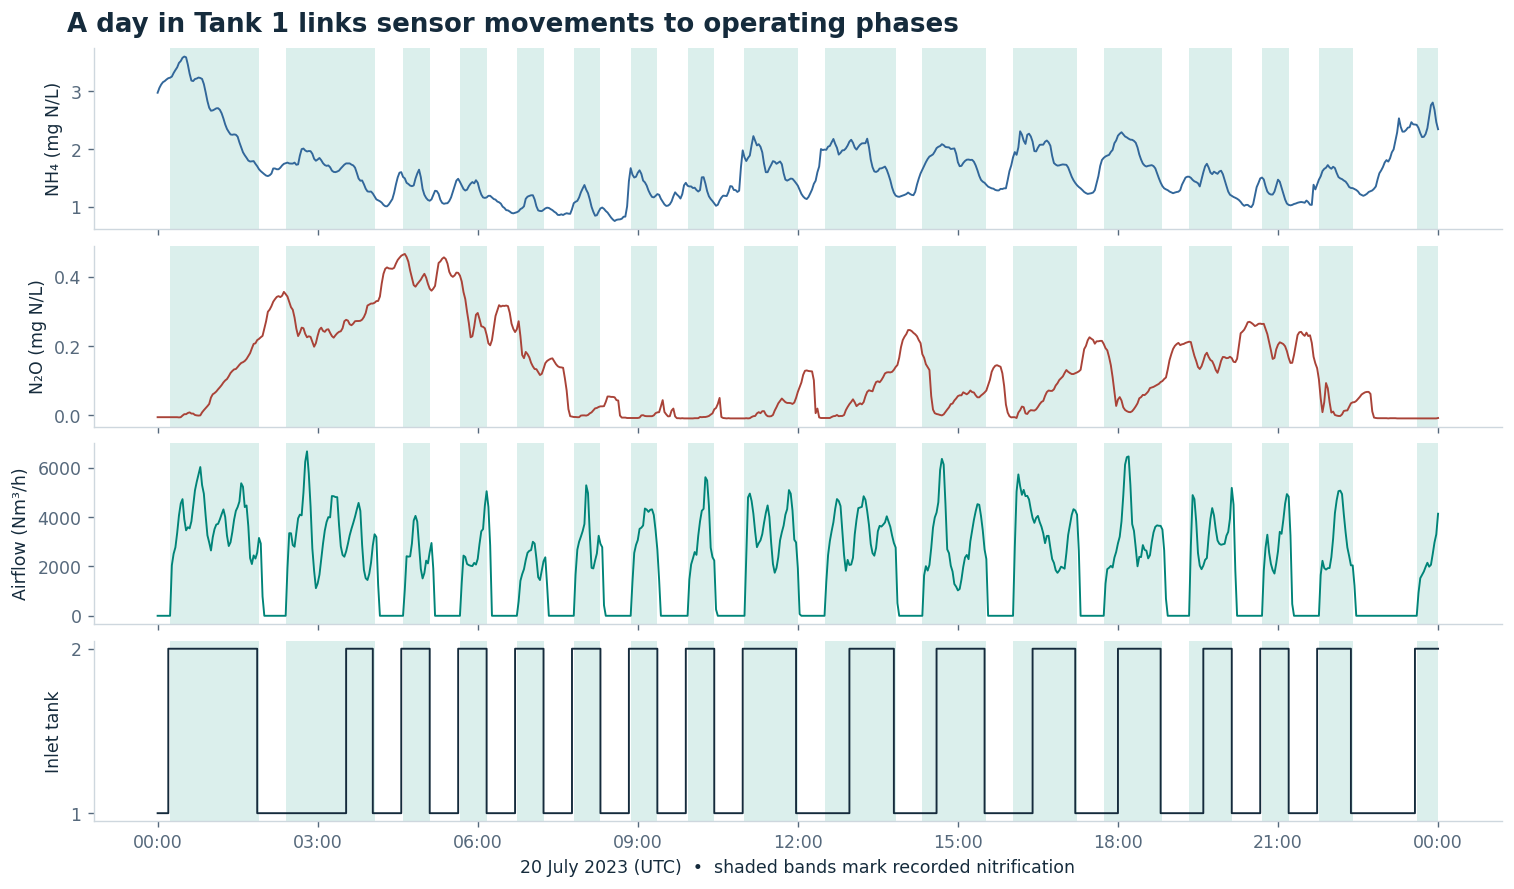

In [7]:
# Show one fixed, high-coverage operating day, with phase bands.
start = pd.Timestamp("2023-07-20", tz="UTC")
view = data.loc[start:start + pd.Timedelta(days=1)]
phase_runs = view["process_phase"].ne(view["process_phase"].shift()).cumsum()
fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
for ax in axes:
    for _, block in view.groupby(phase_runs):
        if block["process_phase"].iloc[0] == 2:
            ax.axvspan(block.index[0] - STEP, block.index[-1], color="#DBEFEC", lw=0)
for ax, column, label, color in zip(
    axes, ["NH4", "N2O", "airflow", "inlet_tank"],
    ["NH₄ (mg N/L)", "N₂O (mg N/L)", "Airflow (Nm³/h)", "Inlet tank"],
    [BLUE, RUST, TEAL, INK],
):
    if column == "inlet_tank":
        ax.step(view.index, view[column], where="post", lw=1.1, color=color)
        ax.set_yticks([1, 2])
    else:
        ax.plot(view.index, view[column], lw=1.1, color=color)
    ax.set_ylabel(label)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[-1].set_xlabel("20 July 2023 (UTC)  •  shaded bands mark recorded nitrification")
fig.suptitle("A day in Tank 1 links sensor movements to operating phases",
             x=0.04, ha="left", fontweight="bold", fontsize=15)
show_figure(fig, "05_operating_day")

## 2. Thirty-minute N₂O baselines

The target is the observed N₂O value 15 bins ahead. Training ends before **1 October 2023**, validation covers October through December, and test begins **1 January 2024**. Both forecast origin and target must stay inside the same split. Feature history may come from an earlier split when it was already available at the forecast origin.

For baseline features only, forward-fill N₂O, NH₄ and airflow by at most three bins (six minutes). The target and categorical states remain unfilled. The replay below uses current readings, N₂O lags of 2, 10, 30 and 60 minutes, trailing means of 10, 30 and 60 minutes, and categorical phase and inlet-tank inputs. Ridge preprocessing and coefficients are fitted on training. The historical second-notebook scores are identified separately because its completed feature-engineering cells were unavailable locally.

In [8]:
split_30 = split_for(HORIZON)
target_n2o = data["N2O"].shift(-HORIZON).rename("observed_N2O")
continuous = ["N2O", "NH4", "airflow"]
states = ["process_phase", "inlet_tank"]
baseline_inputs = data.copy()
baseline_inputs[continuous] = data[continuous].ffill(limit=3)

fill_flags = data.isna() & baseline_inputs.notna()
split_audit = pd.DataFrame({
    "candidate_origins": split_30.value_counts(),
    "observed_targets": target_n2o.notna().groupby(split_30).sum(),
})
split_audit["target_coverage_pct"] = (
    100 * split_audit["observed_targets"] / split_audit["candidate_origins"]
)
display(split_audit.reindex([*SPLITS, "Excluded"]).round(2))
display(fill_flags.groupby(split_30).sum().reindex(SPLITS))

features = baseline_inputs.copy()
for lag in (1, 5, 15, 30):
    features[f"N2O_lag_{lag * 2}min"] = baseline_inputs["N2O"].shift(lag)
rolling_names = {}
for window in (5, 15, 30):
    name = f"N2O_mean_{window * 2}min"
    features[name] = baseline_inputs["N2O"].rolling(window, min_periods=window).mean()
    rolling_names[name] = f"Rolling mean · {window * 2} min"

baseline_ready = features.notna().all(axis=1) & target_n2o.notna()
baseline_train = split_30.eq("Train") & baseline_ready
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), features.columns.difference(states).tolist()),
    ("state", OneHotEncoder(handle_unknown="ignore"), states),
])
ridge = make_pipeline(preprocess, Ridge(alpha=1.0))
ridge.fit(features.loc[baseline_train], target_n2o.loc[baseline_train])

baseline_predictions = {}
replay_rows = []
for split in SPLITS:
    X = features.loc[split_30.eq(split) & baseline_ready]
    pred = X[list(rolling_names)].rename(columns=rolling_names).copy()
    pred.insert(0, "Persistence", X["N2O"])
    pred["Ridge"] = ridge.predict(X)
    baseline_predictions[split] = pred
    replay_rows.append(scores(pred, target_n2o.loc[X.index]).assign(split=split).reset_index())
baseline_replay = pd.concat(replay_rows, ignore_index=True).set_index(["split", "model"])
display(baseline_replay[["n", "MAE", "RMSE", "mean_error"]].round(6))

,candidate_origins,observed_targets,target_coverage_pct
split,,,
Train,342764,270842,79.02
Validation,66225,65495,98.90
Test,117286,114704,97.80
Excluded,45,30,66.67


,N2O,NH4,airflow,process_phase,inlet_tank
split,,,,,
Train,1288,1088,2775,0,0
Validation,686,2027,1754,0,0
Test,164,668,881,0,0


n       MAE      RMSE  mean_error
split      model                                                        
Train      Persistence            207324  0.048240  0.212656    0.000080
           Rolling mean · 10 min  207324  0.051010  0.205199    0.000085
           Rolling mean · 30 min  207324  0.054228  0.179487    0.000043
           Rolling mean · 60 min  207324  0.054048  0.172053   -0.000022
           Ridge                  207324  0.056623  0.163401    0.000000
Validation Persistence             64121  0.011115  0.032273    0.000013
           Rolling mean · 10 min   64121  0.011616  0.030922    0.000009
           Rolling mean · 30 min   64121  0.012443  0.029477   -0.000007
           Rolling mean · 60 min   64121  0.012648  0.028796   -0.000022
           Ridge                   64121  0.021552  0.033524    0.011240
Test       Persistence            109906  0.041507  0.066772    0.000267
           Rolling mean · 10 min  109906  0.044358  0.069270    0.000294
           Rolling mean · 30 min  109906  0.048473  0.074161    0.000360
           Rolling mean · 60 min  109906  0.049299  0.076582    0.000458
           Ridge                  109906  0.041575  0.063985    0.003126

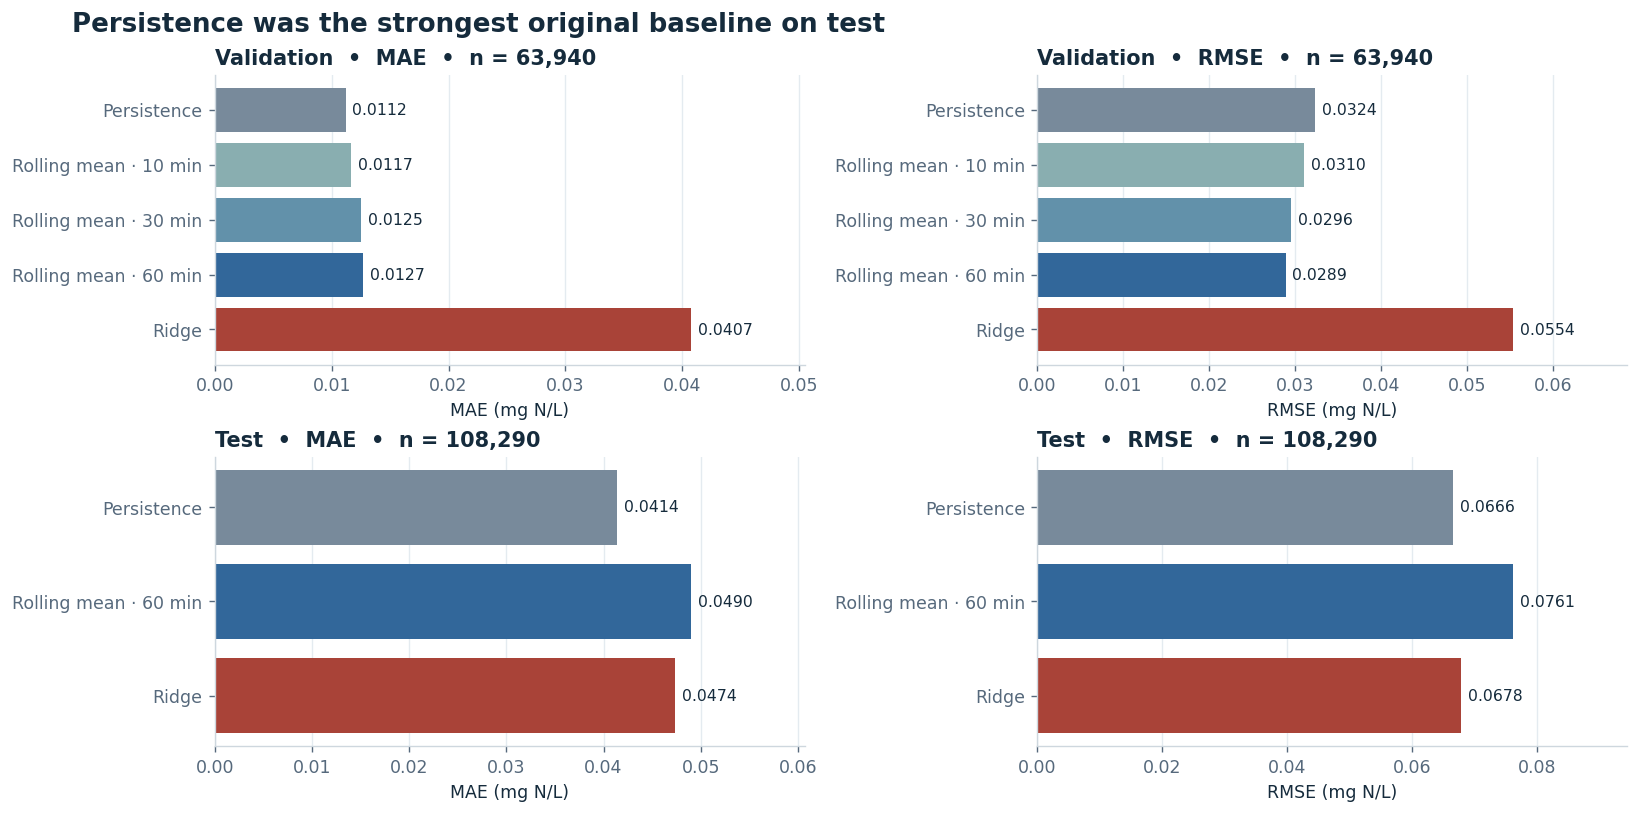

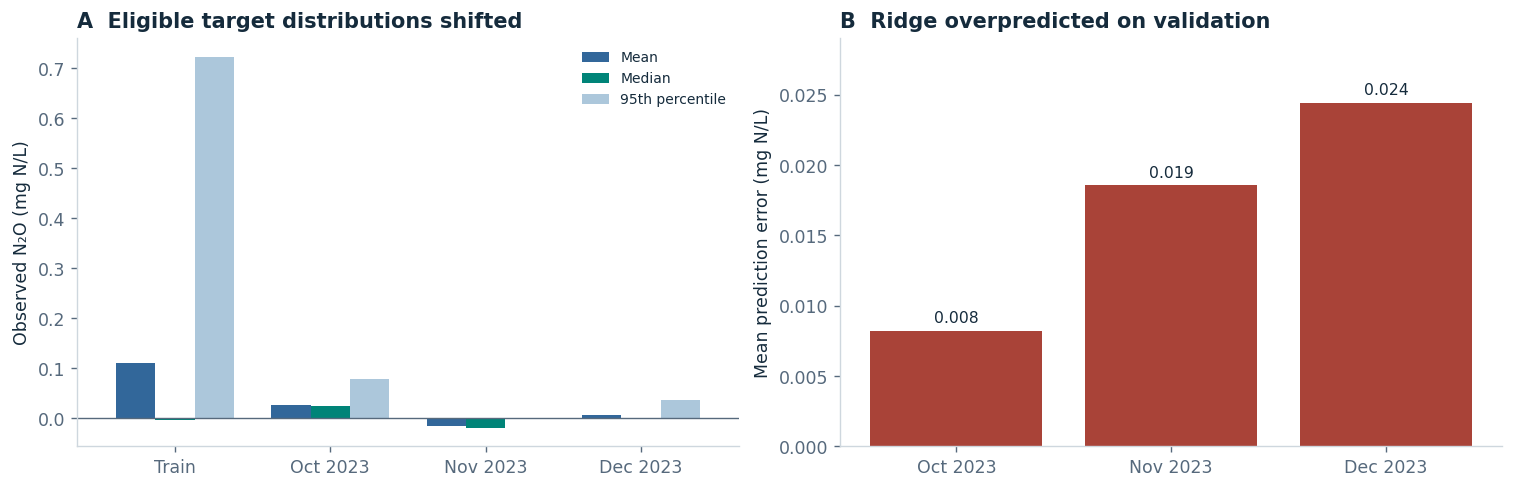

n       MAE      RMSE  mean_error
month_utc model                                             
2023-10   Persistence  20690  0.023872  0.032468   -0.000001
          Ridge        20690  0.033664  0.043811    0.008223
2023-11   Persistence  21290  0.003038  0.042085   -0.000022
          Ridge        21290  0.040716  0.060759    0.018565
2023-12   Persistence  21960  0.007109  0.018432   -0.000032
          Ridge        21960  0.047368  0.059478    0.024410

In [9]:
# Historical results supplied with the original baseline notebook.
historical_baselines = pd.DataFrame([
    ("Train", "Persistence", 206827, .048439, .212723),
    ("Train", "Ridge", 206827, .055995, .152948),
    ("Validation", "Persistence", 63940, .011178, .032366),
    ("Validation", "Rolling mean · 10 min", 63940, .011679, .031016),
    ("Validation", "Rolling mean · 30 min", 63940, .012507, .029584),
    ("Validation", "Rolling mean · 60 min", 63940, .012699, .028908),
    ("Validation", "Ridge", 63940, .040719, .055365),
    ("Test", "Persistence", 108290, .041386, .066587),
    ("Test", "Rolling mean · 60 min", 108290, .048964, .076094),
    ("Test", "Ridge", 108290, .047393, .067753),
], columns=["split", "model", "n", "MAE", "RMSE"]).set_index(["split", "model"])
fig, axes = plt.subplots(2, 2, figsize=(13, 6.4))
for row, split in enumerate(["Validation", "Test"]):
    table = historical_baselines.loc[split]
    for col, metric in enumerate(["MAE", "RMSE"]):
        plot_score_bars(axes[row, col], table, metric,
                        f"{split}  •  {metric}  •  n = {table['n'].iloc[0]:,}")
fig.suptitle("Persistence was the strongest original baseline on test",
             x=0.04, ha="left", fontweight="bold", fontsize=15)
show_figure(fig, "06_historical_baseline_scores")

# Record the original eligible target distributions and validation bias.
historical_targets = pd.DataFrame([
    ("Train", 206827, .110920, -.003472, .723206, 52.62, np.nan),
    ("Oct 2023", 20690, .026336, .023727, .078125, 26.64, .008223),
    ("Nov 2023", 21290, -.016015, -.019097, .001157, 85.03, .018565),
    ("Dec 2023", 21960, .005531, .000000, .037037, 30.46, .024410),
], columns=["period", "n", "mean", "median", "p95", "negative_pct", "ridge_mean_error"]).set_index("period")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
target_plot = historical_targets[["mean", "median", "p95"]].rename(
    columns={"mean": "Mean", "median": "Median", "p95": "95th percentile"}
)
target_plot.plot.bar(ax=axes[0], color=[BLUE, TEAL, "#ACC7DB"], rot=0, width=.76)
axes[0].axhline(0, color=MUTED, lw=.8)
axes[0].set(ylabel="Observed N₂O (mg N/L)", xlabel="")
axes[0].set_title("A  Eligible target distributions shifted", loc="left")
axes[0].legend(fontsize=8)
bias = historical_targets["ridge_mean_error"].dropna()
bars = axes[1].bar(bias.index, bias, color=RUST)
axes[1].bar_label(bars, fmt="%0.3f", padding=3, fontsize=9)
axes[1].set(ylabel="Mean prediction error (mg N/L)", ylim=(0, .029))
axes[1].set_title("B  Ridge overpredicted on validation", loc="left")
show_figure(fig, "07_baseline_distribution_shift")

historical_monthly_baselines = pd.DataFrame([
    ("2023-10", "Persistence", 20690, .023872, .032468, -.000001),
    ("2023-10", "Ridge", 20690, .033664, .043811, .008223),
    ("2023-11", "Persistence", 21290, .003038, .042085, -.000022),
    ("2023-11", "Ridge", 21290, .040716, .060759, .018565),
    ("2023-12", "Persistence", 21960, .007109, .018432, -.000032),
    ("2023-12", "Ridge", 21960, .047368, .059478, .024410),
], columns=["month_utc", "model", "n", "MAE", "RMSE", "mean_error"]).set_index(["month_utc", "model"])
display(historical_monthly_baselines)

The 60-minute mean reduced validation RMSE while increasing validation MAE. Its test MAE and RMSE were both higher than persistence. Ridge also had positive mean error in all three validation months. These results motivate keeping persistence as the paired reference. The baseline and grey-box sections use different eligibility rules, so their original scores have different denominators.

## 3. Grey-box dynamics from Equations 4 and 5

The states are $x_1=\mathrm{NH}_4$ and $x_2=\mathrm{N}_2\mathrm{O}$. Let $u_1$ denote nitrification, $u_2$ denitrification, $u_3$ inflow into Tank 1, and $u_4$ estimated airflow. Set $r_j=\theta_1u_{4,j}+\theta_2$, an ammonia oxidation rate (AOR) proxy. The two discrete-time updates are

$$
x_{1,k+1}=x_{1,k}-u_{1,k-d_1}r_{k-d_1}+u_{3,k-d_1}\theta_5
$$

$$
x_{2,k+1}=x_{2,k}+u_{1,k-d_2}\exp(\theta_3 r_{k-d_2}+\theta_4)
+u_{3,k-d_2}\theta_6+(1-u_{3,k-d_2})\theta_7.
$$

The paper embeds these dynamics in model predictive control, which optimizes future operating actions subject to constraints. Here the equations supply forecasts from observed states and inputs. When a delayed input time falls after the forecast origin, the rollout holds the last available input at the origin. This offline comparison evaluates tank concentration forecasts and does not implement the controller or evaluate emissions reduction. [Equations 4–5 and MPC formulation](https://vbn.aau.dk/ws/portalfiles/portal/823741959/1-s2.0-S2214714425012000-main.pdf)

In [10]:
x1, x2 = data["NH4"], data["N2O"]
phase = data["process_phase"]
u1 = phase.map({0: 0, 1: 0, 2: 1}).rename("u1")
u2 = phase.map({0: 0, 1: 1, 2: 0}).rename("u2")
u3 = data["inlet_tank"].map({1: 1, 2: 0}).rename("u3")
u4 = data["airflow"].rename("u4")
delta_x1 = x1.shift(-1) - x1
delta_x2 = x2.shift(-1) - x2
pair_split = split_for(1)
display(pd.concat([x1.rename("x1"), x2.rename("x2"), u1, u2, u3, u4], axis=1)
        .notna().agg(["sum", "mean"]).T.rename(columns={"sum": "observed", "mean": "coverage"}))

# Equation 4 is linear in theta1, theta2, theta5 at each fixed delay.
nh4_design = pd.DataFrame({"theta1": -u1 * u4, "theta2": -u1, "theta5": u3})
initial_design = nh4_design.shift(10)
initial_ready = initial_design.notna().all(axis=1) & delta_x1.notna()
initial_train = initial_ready & pair_split.eq("Train")
initial_beta = np.linalg.lstsq(initial_design.loc[initial_train],
                              delta_x1.loc[initial_train], rcond=None)[0]
initial_rows = []
for split in ["Train", "Validation"]:
    design = initial_design.loc[initial_ready & pair_split.eq(split)]
    initial = x1.loc[design.index]
    prediction = pd.DataFrame({
        "Persistence": initial, "Grey-box · 20 min": initial + design @ initial_beta,
    })
    initial_rows.append(scores(prediction, x1.shift(-1).loc[design.index])
                        .assign(split=split).reset_index())
nh4_initial_scores = pd.concat(initial_rows, ignore_index=True).set_index(["split", "model"])
display(nh4_initial_scores[["n", "MAE", "RMSE"]].round(6))

delay_steps = range(91)
all_delay_inputs = (
    nh4_design.notna().all(axis=1).rolling(len(delay_steps), min_periods=len(delay_steps))
    .min().eq(1)
)
common_nh4 = delta_x1.notna() & all_delay_inputs
nh4_train = pair_split.eq("Train") & common_nh4
nh4_validation = pair_split.eq("Validation") & common_nh4
nh4_params, nh4_delay_rows = {}, []
for lag in delay_steps:
    design = nh4_design.shift(lag)
    beta = np.linalg.lstsq(design.loc[nh4_train], delta_x1.loc[nh4_train], rcond=None)[0]
    nh4_params[lag] = beta
    val = design.loc[nh4_validation]
    pred = pd.DataFrame({"Persistence": x1.loc[val.index], "Grey-box": x1.loc[val.index] + val @ beta})
    row = scores(pred, x1.shift(-1).loc[val.index]).loc["Grey-box"]
    nh4_delay_rows.append({**dict(zip(design.columns, beta)), **row.to_dict(),
                           "delay_min": 2 * lag})
nh4_delay = pd.DataFrame(nh4_delay_rows).set_index("delay_min")
print(f"Common one-step pairs  •  train {nh4_train.sum():,}  •  validation {nh4_validation.sum():,}")
display(nh4_delay.nsmallest(5, "RMSE")[["theta1", "theta2", "theta5", "MAE", "RMSE"]].round(6))

# For this rollout, retain only the five delay candidates from the project.
rollout_lags = [10, 11, 12, 13, 14]
nh4_target = x1.shift(-HORIZON)
nh4_rollout = pd.DataFrame({"Persistence": x1})
for lag in rollout_lags:
    cumulative_inputs = sum(nh4_design.shift(max(lag - h, 0)) for h in range(HORIZON))
    nh4_rollout[f"{lag * 2} min"] = x1 + cumulative_inputs @ nh4_params[lag]
nh4_rollout = nh4_rollout.loc[
    split_30.eq("Validation") & nh4_target.notna() & nh4_rollout.notna().all(axis=1)
]
nh4_rollout_scores = scores(nh4_rollout, nh4_target.loc[nh4_rollout.index])
nh4_rollout_scores["negative_prediction_pct"] = 100 * nh4_rollout.lt(0).mean()
nh4_delay_choice = nh4_rollout_scores.drop(index="Persistence")["RMSE"].idxmin()
nh4_choice_steps = int(nh4_delay_choice.split()[0]) // 2
theta1, theta2, theta5 = nh4_params[nh4_choice_steps]
display(nh4_rollout_scores.round(6))

Common one-step pairs  •  train 137,709  •  validation 35,485


,observed,coverage
x1,464147.0,0.881872
x2,451086.0,0.857057
u1,516978.0,0.982250
u2,516978.0,0.982250
u3,522001.0,0.991794
u4,464397.0,0.882347


n       MAE      RMSE
split      model                                        
Train      Persistence        236119  0.082106  0.116960
           Grey-box · 20 min  236119  0.066920  0.095601
Validation Persistence         59429  0.090315  0.197451
           Grey-box · 20 min   59429  0.117262  0.188803

,theta1,theta2,theta5,MAE,RMSE
delay_min,,,,,
24,0.000008,0.036449,0.066297,0.112767,0.182490
26,0.000004,0.048170,0.062888,0.110851,0.182626
22,0.000013,0.022725,0.068338,0.114116,0.182744
28,0.000000,0.056935,0.057771,0.108607,0.183177
20,0.000017,0.007789,0.068543,0.115481,0.183616


,n,MAE,RMSE,mean_error,MAE_improvement_pct,RMSE_improvement_pct,negative_prediction_pct
model,,,,,,,
Persistence,50224,0.993286,1.296827,0.005232,0.000000,0.000000,0.000000
20 min,50224,0.625840,0.903902,-0.077116,36.992987,30.298987,2.502788
22 min,50224,0.611122,0.890562,-0.071917,38.474713,31.327657,2.315626
24 min,50224,0.612600,0.890708,-0.065514,38.325856,31.316390,2.214081
26 min,50224,0.630509,0.905787,-0.054953,36.522928,30.153572,2.096607
28 min,50224,0.664037,0.937244,-0.042743,33.147443,27.727881,1.967187


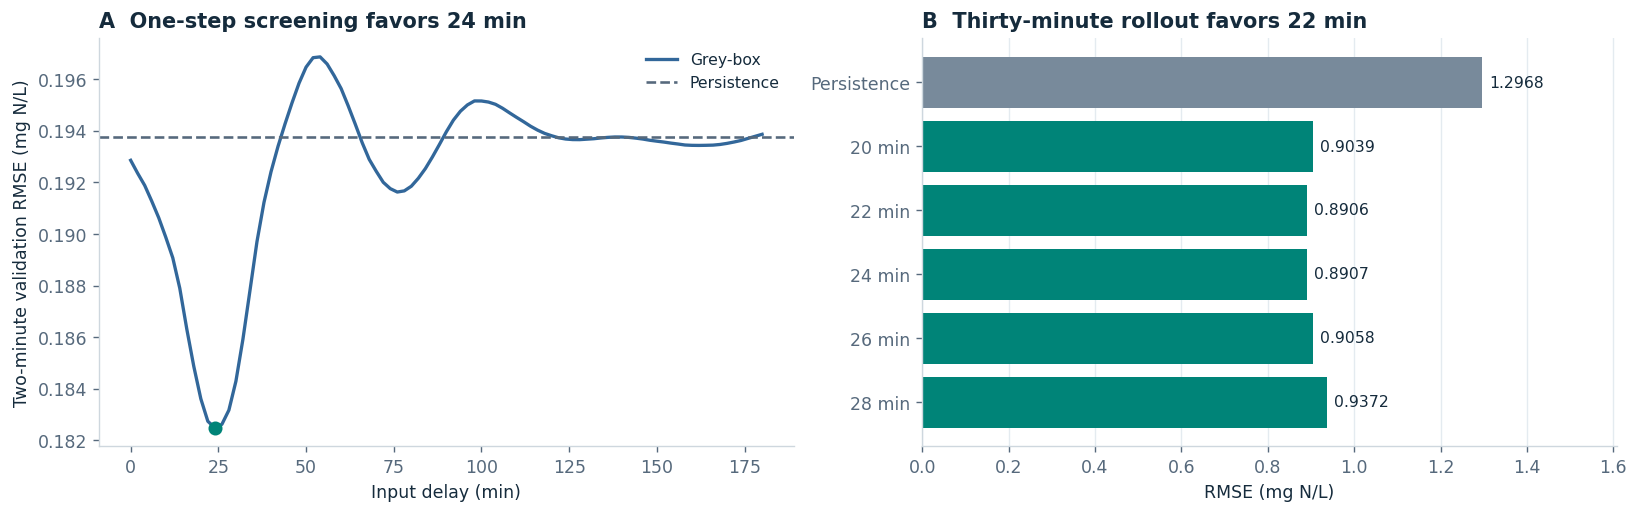

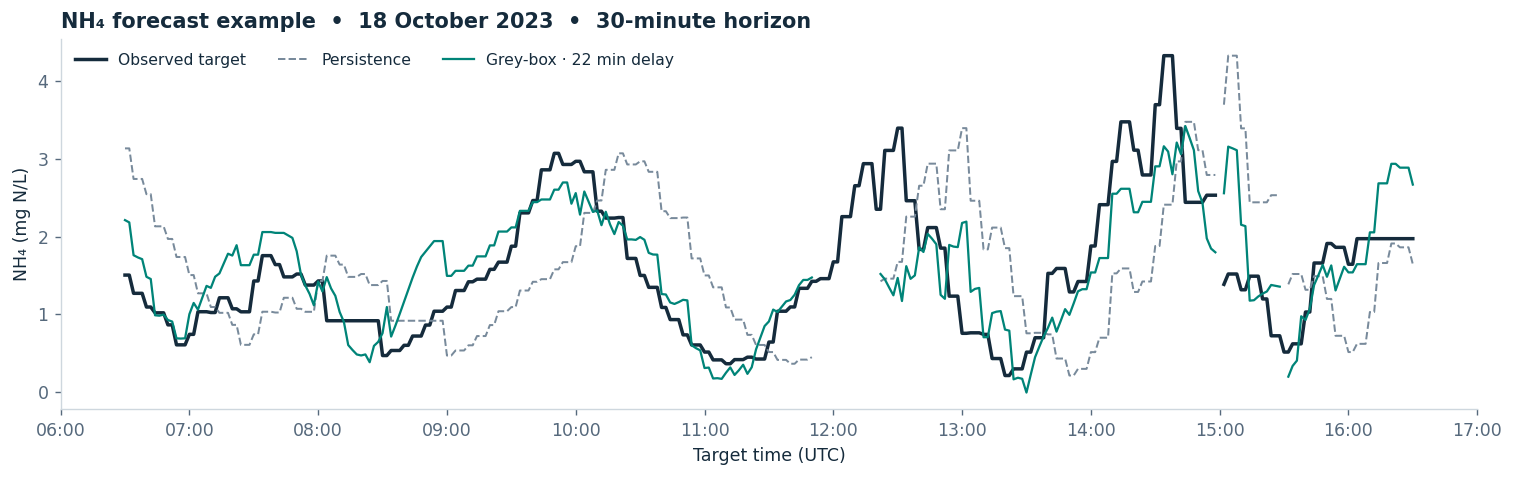

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(nh4_delay.index, nh4_delay["RMSE"], color=BLUE, lw=1.9, label="Grey-box")
baseline_rmse = np.sqrt(delta_x1[nh4_validation].pow(2).mean())
ax.axhline(baseline_rmse, color=MUTED, ls="--", label="Persistence")
best_lag = nh4_delay["RMSE"].idxmin()
ax.scatter(best_lag, nh4_delay.at[best_lag, "RMSE"], s=50, color=TEAL, zorder=3)
ax.set(xlabel="Input delay (min)", ylabel="Two-minute validation RMSE (mg N/L)")
ax.set_title(f"A  One-step screening favors {best_lag} min", loc="left")
ax.legend(fontsize=9)
plot_score_bars(axes[1], nh4_rollout_scores[["RMSE"]], "RMSE",
                f"B  Thirty-minute rollout favors {nh4_delay_choice}")
show_figure(fig, "08_nh4_delay_and_rollout")

example_clock = pd.date_range(
    "2023-10-18 06:00", "2023-10-18 16:00", freq=STEP, tz="UTC"
)
example = nh4_rollout.reindex(example_clock)
fig, ax = plt.subplots(figsize=(12, 3.7))
target_clock = example.index + HORIZON * STEP
ax.plot(target_clock, nh4_target.loc[example.index], color=INK, lw=2, label="Observed target")
ax.plot(target_clock, example["Persistence"], color=COLORS["Persistence"], lw=1.15,
        ls="--", label="Persistence")
ax.plot(target_clock, example[nh4_delay_choice], color=TEAL, lw=1.3,
        label=f"Grey-box · {nh4_delay_choice} delay")
ax.set(xlabel="Target time (UTC)", ylabel="NH₄ (mg N/L)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_title("NH₄ forecast example  •  18 October 2023  •  30-minute horizon", loc="left")
ax.legend(ncol=3, fontsize=9)
show_figure(fig, "09_nh4_forecast_example")

### N₂O identification and diagnostics

One-step N₂O increments are often zero, and occasional large jumps dominate squared error. In the original direct one-step fits, the exponential formation contribution shrank nearly to zero across starting values and both fitting losses. The fit could converge numerically while leaving the formation parameters poorly identified.

A phase-based estimator uses the mean increment within each complete phase. Estimate $\theta_6$ and $\theta_7$ from denitrification steps by inlet state. Then subtract those contributions from nitrification phase means and fit the exponential formation term. Weighting denitrification phases equally gave a different sign for the no-inflow coefficient in the original analysis, so the step-level conditional estimates are retained for this rollout.

,n,median,p95
split,,,
Train,149164,0.067908,0.098197
Validation,35033,0.070893,0.098545


,n,min,max,abs_increment_p95,zero_pct
split,,,,,
Train,269661,-12.023727,12.023148,0.027199,35.750442
Validation,64838,-1.157407,2.067708,0.007523,52.833215


,MAE,RMSE,formation_p95_train
model,,,
Persistence,0.001662,0.011929,NaN
Direct grey-box · linear,0.002034,0.011942,6.960000e-14
Direct grey-box · Soft-L1,0.001920,0.011940,3.240000e-14


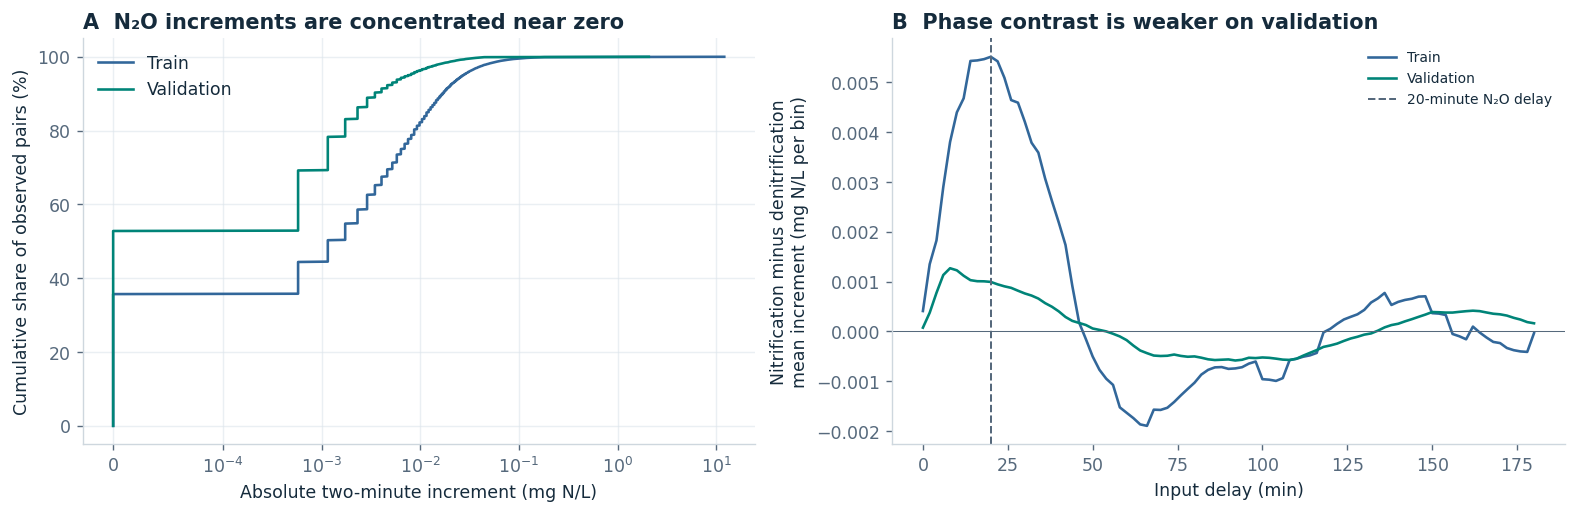

In [12]:
aor = theta1 * u4 + theta2
aor_summary = aor.where(u1.eq(1)).groupby(pair_split).agg(
    n="count", median="median", p95=lambda s: s.quantile(.95)
)
display(aor_summary.loc[["Train", "Validation"]].round(6))
increments = pd.DataFrame([
    {
        "split": split, "n": len(y), "min": y.min(), "max": y.max(),
        "abs_increment_p95": y.abs().quantile(.95), "zero_pct": 100 * y.eq(0).mean(),
    }
    for split in ["Train", "Validation"]
    for y in [delta_x2.loc[pair_split.eq(split)].dropna()]
]).set_index("split")
display(increments.round(6))

# Direct one-step results from the original project, on 62,101 validation pairs.
direct_fit = pd.DataFrame([
    ("Persistence", .001662, .011929, np.nan),
    ("Direct grey-box · linear", .002034, .011942, 6.96e-14),
    ("Direct grey-box · Soft-L1", .001920, .011940, 3.24e-14),
], columns=["model", "MAE", "RMSE", "formation_p95_train"]).set_index("model")
display(direct_fit)

n2o_pair_ready = delta_x2.notna() & all_delay_inputs
contrast_rows = []
for lag in delay_steps:
    lag_phase = phase.shift(lag)
    for split in ("Train", "Validation"):
        mask = n2o_pair_ready & pair_split.eq(split)
        nit = delta_x2.loc[mask & lag_phase.eq(2)]
        denit = delta_x2.loc[mask & lag_phase.eq(1)]
        contrast_rows.append({
            "delay_min": lag * 2, "split": split, "n_nit": len(nit),
            "n_denit": len(denit), "mean_contrast": nit.mean() - denit.mean(),
            "median_contrast": nit.median() - denit.median(),
        })
lag_contrast = pd.DataFrame(contrast_rows)
contrast = lag_contrast.pivot(index="delay_min", columns="split", values="mean_contrast")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
ax = axes[0]
for split, color in [("Train", BLUE), ("Validation", TEAL)]:
    values = delta_x2.loc[pair_split.eq(split)].dropna()
    quantiles = np.linspace(0, 1, 1001)
    ax.plot(values.abs().quantile(quantiles), 100 * quantiles, label=split, color=color)
ax.set_xscale("symlog", linthresh=1e-4)
ax.set(xlabel="Absolute two-minute increment (mg N/L)",
       ylabel="Cumulative share of observed pairs (%)")
ax.set_title("A  N₂O increments are concentrated near zero", loc="left")
ax.legend()
ax.grid(alpha=.6)
ax = axes[1]
for split, color in [("Train", BLUE), ("Validation", TEAL)]:
    ax.plot(contrast.index, contrast[split], label=split, color=color)
ax.axvline(20, color=MUTED, ls="--", lw=1.15, label="20-minute N₂O delay")
ax.axhline(0, color=MUTED, lw=.6)
ax.set(xlabel="Input delay (min)", ylabel="Nitrification minus denitrification\nmean increment (mg N/L per bin)")
ax.set_title("B  Phase contrast is weaker on validation", loc="left")
ax.legend(fontsize=8)
show_figure(fig, "10_n2o_increment_and_delay")

In [13]:
N2O_DELAY_STEPS = 10
phase_source = pd.DataFrame({"phase": phase, "u1": u1, "u3": u3, "aor": aor}).shift(N2O_DELAY_STEPS)
phase_source["delta"] = delta_x2
phase_source["split"] = pair_split
phase_source["clock"] = grid_index
phase_id = phase_source["phase"].ne(phase_source["phase"].shift()).cumsum().rename("phase_id")
runs = phase_source.groupby(phase_id).agg(
    phase=("phase", "first"), split=("split", "first"), end_split=("split", "last"),
    n=("clock", "size"), started=("clock", "min"), last_step=("clock", "max"),
    n_delta=("delta", "count"), n_u3=("u3", "count"), n_aor=("aor", "count"),
    mean_delta=("delta", "mean"), mean_aor=("aor", "mean"), inflow_fraction=("u3", "mean"),
)
eligible_run = (
    runs["phase"].isin([1, 2])
    & runs["phase"].shift(1).isin([0, 1, 2])
    & runs["phase"].shift(-1).isin([0, 1, 2])
    & runs["split"].eq(runs["end_split"])
    & runs["split"].isin(SPLITS)
    & runs["n_delta"].eq(runs["n"])
    & runs["n_u3"].eq(runs["n"])
    & runs["n_aor"].eq(runs["n"])
)
phases = runs.loc[eligible_run].copy()
phases["available"] = phases["last_step"] + STEP
phase_steps = phase_source.loc[phase_id.isin(phases.index)].assign(phase_id=phase_id)
dn_ids = phases.index[phases["phase"].eq(1)]
dn_steps = phase_steps.loc[phase_steps["phase_id"].isin(dn_ids)]
train_dn = dn_steps.loc[dn_steps["split"].eq("Train")]
theta6_theta7 = train_dn.groupby("u3")["delta"].mean()
theta6, theta7 = theta6_theta7.loc[1], theta6_theta7.loc[0]

phase_summary = phases.groupby(["split", "phase"]).agg(
    n_phases=("n", "size"), retained_steps=("n", "sum"), median_steps=("n", "median"),
    median_aor=("mean_aor", "median"), median_mean_increment=("mean_delta", "median"),
)
display(phase_summary.round(6))
display(train_dn.groupby("u3")["delta"].agg(["count", "mean", "median"]).round(7))
dn_train_phases = phases.loc[phases["split"].eq("Train") & phases["phase"].eq(1)]
inflow_fraction = dn_train_phases["inflow_fraction"].to_numpy()
equal_phase_additive = np.linalg.lstsq(
    np.column_stack([inflow_fraction, 1 - inflow_fraction]),
    dn_train_phases["mean_delta"], rcond=None,
)[0]
display(pd.DataFrame(
    [equal_phase_additive, [theta6, theta7]],
    index=["Equal phase weights", "Step conditional means"],
    columns=["theta6", "theta7"],
).round(7))

# The static Soft-L1 coefficients were frozen in the original project.
THETA3 = 5.441838838709096
THETA4 = -5.814089615583807
STATIC_AMPLITUDE = np.exp(THETA4)
phase_shape = np.exp(THETA3 * phase_steps["aor"]).groupby(phase_steps["phase_id"]).mean()
phases["shape"] = phase_shape
phases["adjusted_formation"] = (
    phases["mean_delta"] - theta6 * phases["inflow_fraction"]
    - theta7 * (1 - phases["inflow_fraction"])
)
formation = phases.loc[phases["phase"].eq(2)]

# Independent training fit for comparison with the saved static template.
training_nit = formation.loc[formation["split"].eq("Train")]
nit_steps = phase_steps.loc[phase_steps["phase_id"].isin(training_nit.index)]
nit_codes = pd.Categorical(nit_steps["phase_id"], categories=training_nit.index).codes
nit_aor = nit_steps["aor"].to_numpy()
nit_counts = training_nit["n"].to_numpy()
formation_target = training_nit["adjusted_formation"].to_numpy()

def phase_formation_residual(params):
    per_step = np.exp(params[0] * nit_aor + params[1])
    return np.bincount(nit_codes, weights=per_step) / nit_counts - formation_target

refit = least_squares(
    phase_formation_residual, [5., -6.], bounds=([-100, -30], [100, 5]),
    loss="soft_l1", f_scale=max(np.quantile(np.abs(formation_target), .95), 1e-6),
)
display(pd.DataFrame(
    [[THETA3, THETA4], refit.x], index=["Frozen original", "Training replay"],
    columns=["theta3", "theta4"],
).round(6))

# Compare the static increment with a zero-increment phase forecast.
validation_nit = formation.loc[formation["split"].eq("Validation")]
validation_inc = validation_nit["mean_delta"]
static_phase_inc = (
    STATIC_AMPLITUDE * validation_nit["shape"]
    + theta6 * validation_nit["inflow_fraction"]
    + theta7 * (1 - validation_nit["inflow_fraction"])
)
phase_predictions = pd.DataFrame({"Persistence": 0., "Static grey-box": static_phase_inc})
display(scores(phase_predictions, validation_inc)[["n", "MAE", "RMSE", "mean_error"]].round(7))

n_phases  retained_steps  ...  median_aor  median_mean_increment
split      phase                            ...                                   
Test       1.0        1444           32639  ...    0.025416              -0.001157
           2.0        1404           49325  ...    0.074674               0.000644
Train      1.0        3718           79407  ...    0.025645              -0.001085
           2.0        3617           95535  ...    0.066584               0.000883
Validation 1.0         687           17778  ...    0.024062              -0.000070
           2.0         718           26034  ...    0.070256               0.000044

[6 rows x 5 columns]

,count,mean,median
u3,,,
0.0,7110,-0.001889,0.0
1.0,72297,-0.003414,0.0


,theta6,theta7
Equal phase weights,-0.004102,0.006740
Step conditional means,-0.003414,-0.001889


,theta3,theta4
Frozen original,5.441839,-5.814090
Training replay,5.441279,-5.814051


,n,MAE,RMSE,mean_error
model,,,,
Persistence,718,0.000525,0.001525,-0.000421
Static grey-box,718,0.001760,0.002227,0.001657


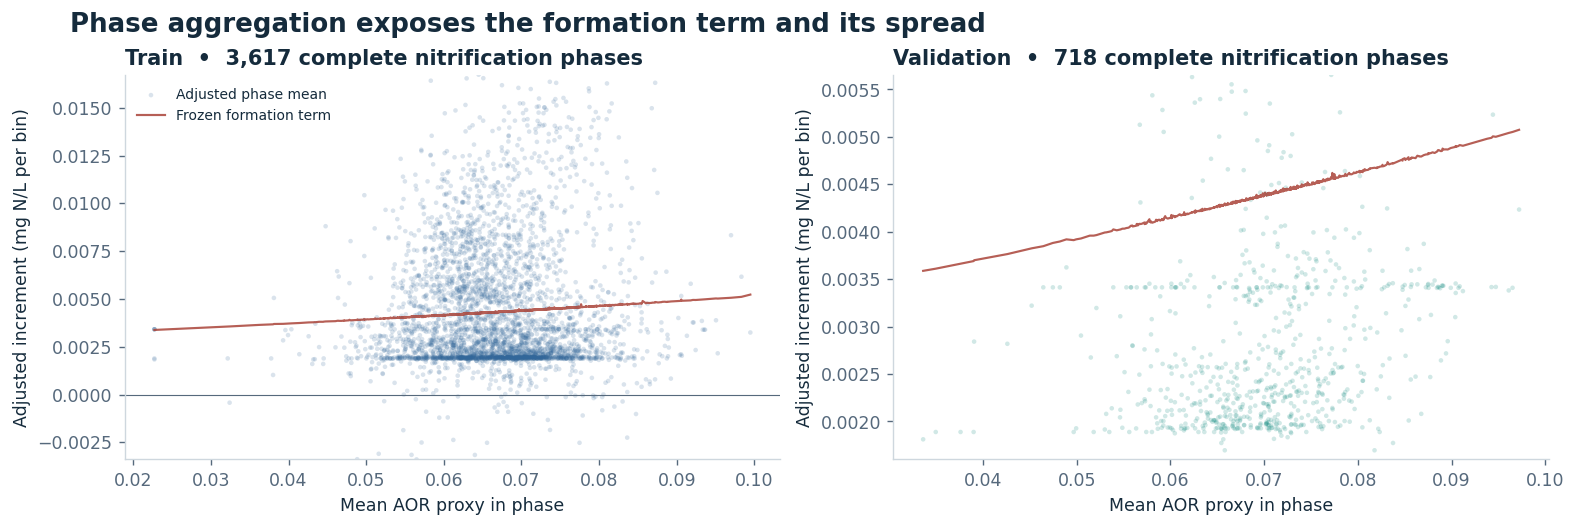

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.1))
for ax, split, color in zip(axes, ["Train", "Validation"], [BLUE, TEAL]):
    s = formation.loc[formation["split"].eq(split)]
    ax.scatter(s["mean_aor"], s["adjusted_formation"], s=7, alpha=.18,
               edgecolor="none", color=color, label="Adjusted phase mean")
    order = s["mean_aor"].sort_values().index
    ax.plot(s.loc[order, "mean_aor"], STATIC_AMPLITUDE * s.loc[order, "shape"],
            lw=1.25, alpha=.85, color=RUST, label="Frozen formation term")
    ax.axhline(0, color=MUTED, lw=.65)
    limits = s["adjusted_formation"].quantile([.005, .99])
    ax.set(ylim=(limits.iloc[0], limits.iloc[1]), xlabel="Mean AOR proxy in phase",
           ylabel="Adjusted increment (mg N/L per bin)")
    ax.set_title(f"{split}  •  {len(s):,} complete nitrification phases", loc="left")
axes[0].legend(fontsize=8)
fig.suptitle("Phase aggregation exposes the formation term and its spread",
             x=.04, ha="left", fontsize=15, fontweight="bold")
show_figure(fig, "11_phase_formation")

## 4. Walk-forward N₂O evaluation

Freeze the 20-minute input delay, the NH₄-derived AOR coefficients and the exponential slope. At 00:00 UTC each day, use a trailing 3-day or 7-day window of complete phases. A phase must start within the window and its final observation must have been available **strictly before** the update. Require at least five nitrification and five denitrification phases and at least 20 denitrification steps in each inlet state.

Estimate the two additive terms from the available denitrification steps. Fit the nonnegative formation amplitude $A=e^{\theta_4}$ to the nitrification phase means with a Soft-L1 loss. Use persistence when history is insufficient, the fitted amplitude is zero, or the fit fails. One daily fit applies to the whole forecast horizon. The 7-day window is the original validation-selected protocol. Earlier completed test phases can inform later test forecasts.

The comparison includes the static Soft-L1 model and both rolling models on the same eligible origins. These require observed initial and target concentrations and valid delayed control histories in phases 1 and 2. Forecast coverage and fallback frequency have different denominators.

In [15]:
MIN_PHASES = 5
MIN_DN_STEPS = 20
WINDOWS = [7, 3]

def fit_amplitude(shape, observed):
    # Soft-L1 convex loss in the nonnegative amplitude.
    scale = max(float(np.quantile(np.abs(observed), .95)), 1e-6)

    def derivative(amplitude):
        residual = amplitude * shape - observed
        return np.sum(shape * residual / np.hypot(1, residual / scale))

    if derivative(0.) >= 0:
        return 0.
    upper = max(1., np.max(observed / shape))
    return brentq(derivative, 0., upper, xtol=1e-14)

def daily_schedule(update_times):
    rows = []
    for window_days in WINDOWS:
        for update in update_times:
            history = phases.loc[
                phases["started"].ge(update - pd.Timedelta(days=window_days))
                & phases["available"].lt(update)
            ]
            nit = history.loc[history["phase"].eq(2)]
            dn = history.loc[history["phase"].eq(1)]
            local_steps = dn_steps.loc[dn_steps["phase_id"].isin(dn.index)]
            state_counts = local_steps["u3"].value_counts().reindex([0., 1.], fill_value=0)
            row = {
                "window_days": window_days, "update_time_utc": update,
                "latest_available_utc": history["available"].max(), "n_nit_phases": len(nit),
                "n_denit_phases": len(dn), "n_denit_noinflow_steps": state_counts.loc[0.],
                "n_denit_inflow_steps": state_counts.loc[1.], "status": "Insufficient history",
                "amplitude": np.nan, "theta4": np.nan, "theta6": np.nan, "theta7": np.nan,
            }
            if min(len(nit), len(dn)) >= MIN_PHASES and state_counts.min() >= MIN_DN_STEPS:
                means = local_steps.groupby("u3")["delta"].mean()
                observed = (nit["mean_delta"] - nit["inflow_fraction"] * means.loc[1.]
                            - (1 - nit["inflow_fraction"]) * means.loc[0.])
                try:
                    amplitude = fit_amplitude(nit["shape"].to_numpy(), observed.to_numpy())
                except (ValueError, RuntimeError, FloatingPointError):
                    row["status"] = "Fit failed"
                else:
                    if amplitude > 0:
                        row.update(status="Fit used", amplitude=amplitude, theta4=np.log(amplitude),
                                   theta6=means.loc[1.], theta7=means.loc[0.])
                    else:
                        row["status"] = "Zero amplitude"
            rows.append(row)
    schedule = pd.DataFrame(rows)
    available = schedule["latest_available_utc"].notna()
    assert (schedule.loc[available, "latest_available_utc"]
            < schedule.loc[available, "update_time_utc"]).all()
    return schedule

active = phase.isin([1, 2])
per_step = pd.DataFrame({
    "formation": u1 * np.exp(THETA3 * aor), "inflow": u3, "no_inflow": 1 - u3,
}).where(active, axis=0)
basis = sum(per_step.shift(max(N2O_DELAY_STEPS - h, 0)) for h in range(HORIZON))
gb_ready = x2.notna() & target_n2o.notna() & basis.notna().all(axis=1)
schedule = daily_schedule(pd.date_range(
    VALIDATION_START, grid_index.max().normalize(), freq="D"
))
schedule["split"] = np.where(schedule["update_time_utc"].lt(TEST_START), "Validation", "Test")

gb_predictions, gb_usage, gb_rows = {}, {}, []
for split in ["Validation", "Test"]:
    index = grid_index[gb_ready & split_30.eq(split)]
    init, b = x2.loc[index], basis.loc[index]
    pred = pd.DataFrame({
        "Persistence": init,
        "Static grey-box": init + STATIC_AMPLITUDE * b["formation"]
                          + theta6 * b["inflow"] + theta7 * b["no_inflow"],
    })
    used = pd.DataFrame(index=index)
    for window_days in WINDOWS:
        name = f"Rolling · {window_days} days"
        daily = schedule.loc[schedule["window_days"].eq(window_days)]
        params = daily.set_index("update_time_utc").sort_index().reindex(index, method="ffill")
        candidate = (init + params["amplitude"] * b["formation"]
                     + params["theta6"] * b["inflow"] + params["theta7"] * b["no_inflow"])
        used[name] = params["status"].eq("Fit used") & np.isfinite(candidate)
        pred[name] = candidate.where(used[name], init)
    table = scores(pred, target_n2o.loc[index])
    table["fallback_pct"] = 100 * (~used).mean()
    table["candidate_origins"] = int(split_30.eq(split).sum())
    table["coverage_pct"] = 100 * table["n"] / table["candidate_origins"]
    gb_rows.append(table.assign(split=split).reset_index())
    gb_predictions[split] = pred
    gb_usage[split] = used

greybox_metrics = pd.concat(gb_rows, ignore_index=True).set_index(["split", "model"])
test_pred = gb_predictions["Test"]
test_used = gb_usage["Test"]
test_monthly = monthly_scores(test_pred, target_n2o.loc[test_pred.index], test_used)
update_counts = schedule.groupby(["split", "window_days", "status"]).size().unstack(fill_value=0)
display(update_counts)
display(greybox_metrics[["n", "coverage_pct", "MAE", "RMSE", "mean_error", "fallback_pct"]].round(6))

status                  Fit used  Insufficient history  Zero amplitude
split      window_days                                                
Test       3                 100                    62               1
           7                 150                    13               0
Validation 3                  63                    23               6
           7                  76                     8               8

n  coverage_pct  ...  mean_error  fallback_pct
split      model                                  ...                          
Validation Persistence       49241     74.354096  ...   -0.000017           NaN
           Static grey-box   49241     74.354096  ...   -0.000964           NaN
           Rolling · 7 days  49241     74.354096  ...    0.000211     14.061453
           Rolling · 3 days  49241     74.354096  ...    0.000144     24.780163
Test       Persistence       99678     84.987125  ...   -0.000145           NaN
           Static grey-box   99678     84.987125  ...    0.000890           NaN
           Rolling · 7 days  99678     84.987125  ...   -0.001075      7.203194
           Rolling · 3 days  99678     84.987125  ...   -0.000760     37.094444

[8 rows x 6 columns]

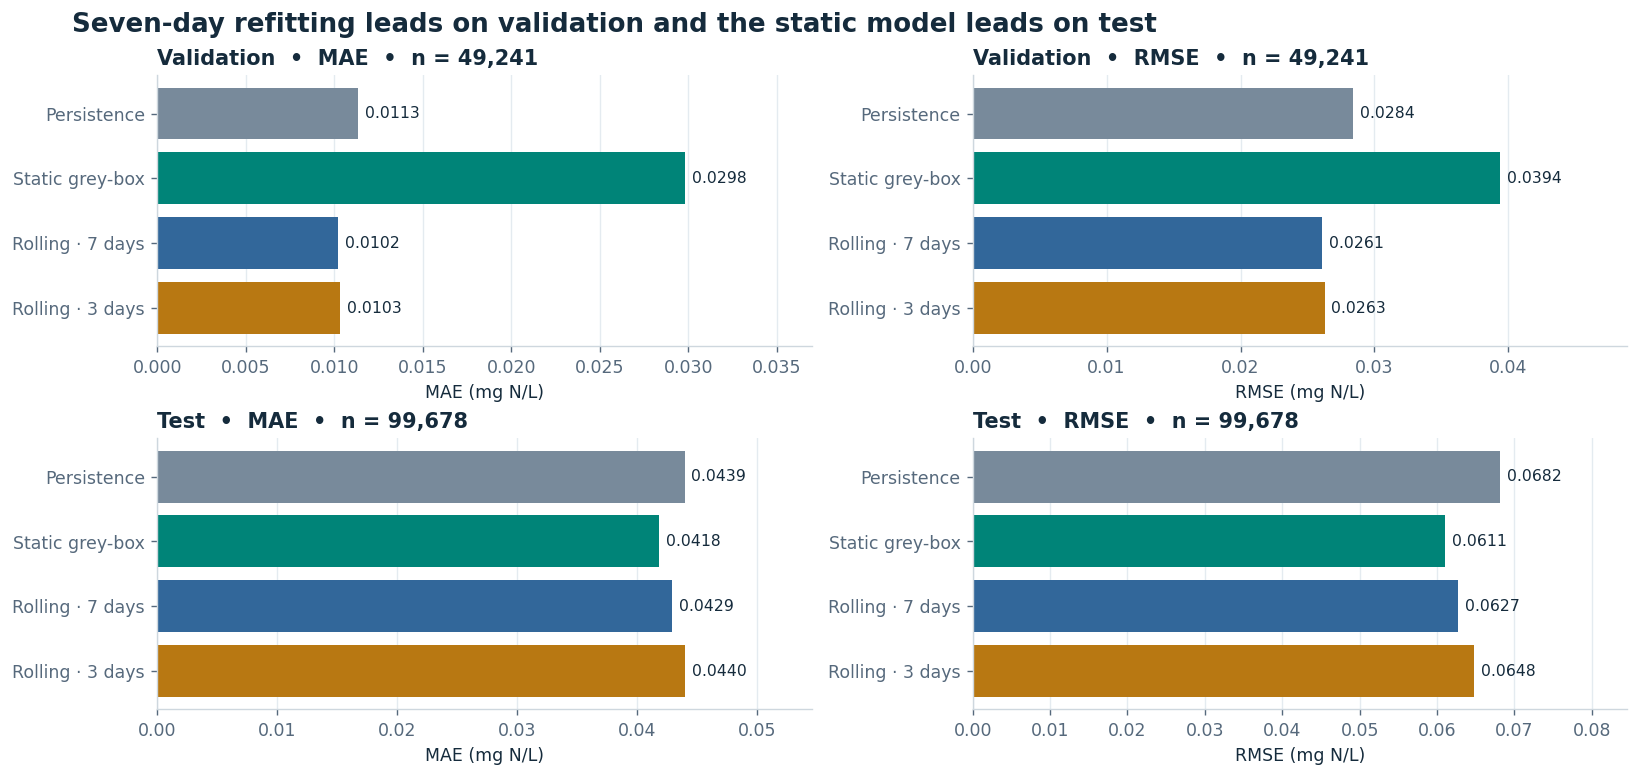

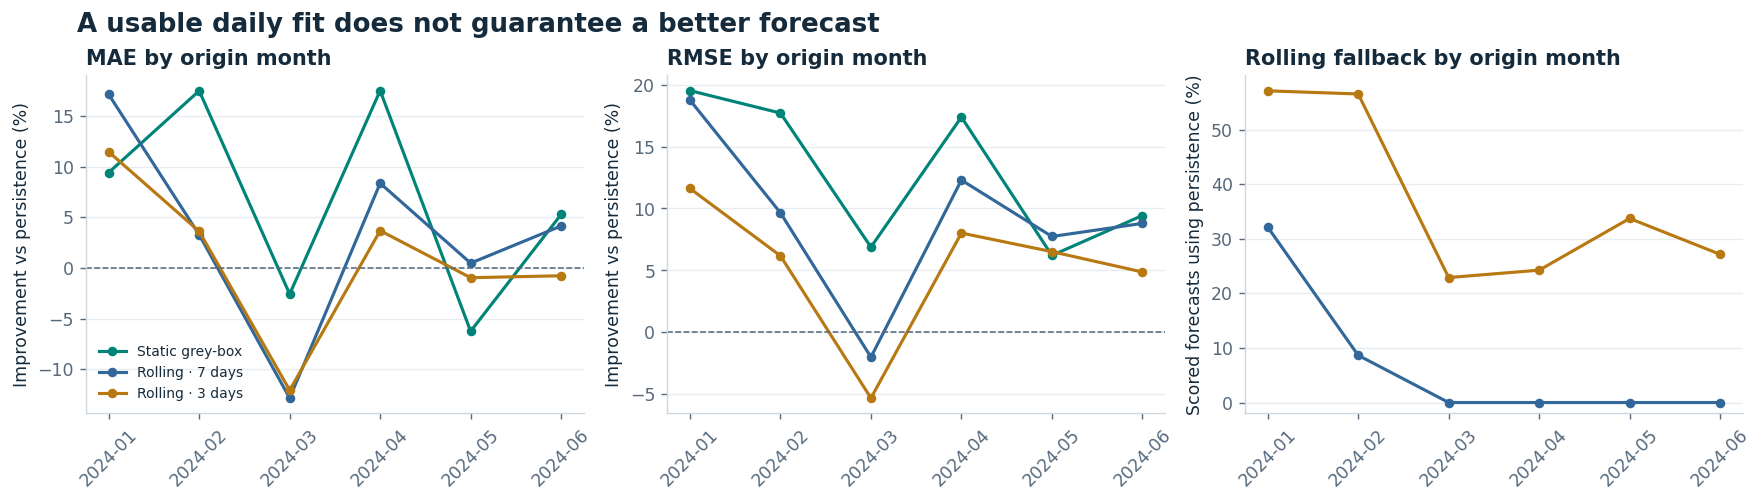

n     MAE  ...  RMSE_improvement_pct  fallback_pct
month_utc model                            ...                                    
2024-01   Persistence       18275  0.0276  ...                0.0000           NaN
          Static grey-box   18275  0.0250  ...               19.5133           NaN
          Rolling · 7 days  18275  0.0229  ...               18.7478       32.1477
          Rolling · 3 days  18275  0.0244  ...               11.6166       57.1272
2024-02   Persistence       15080  0.0333  ...                0.0000           NaN
          Static grey-box   15080  0.0275  ...               17.7021           NaN
          Rolling · 7 days  15080  0.0322  ...                9.6507        8.6538
          Rolling · 3 days  15080  0.0321  ...                6.1793       56.5517
2024-03   Persistence       19262  0.0404  ...                0.0000           NaN
          Static grey-box   19262  0.0414  ...                6.8836           NaN
          Rolling · 7 days  19262  0.0455  ...               -1.9969        0.0000
          Rolling · 3 days  19262  0.0452  ...               -5.3001       22.9052
2024-04   Persistence       18772  0.0435  ...                0.0000           NaN
          Static grey-box   18772  0.0359  ...               17.3772           NaN
          Rolling · 7 days  18772  0.0399  ...               12.2931        0.0000
          Rolling · 3 days  18772  0.0419  ...                8.0201       24.2595
2024-05   Persistence       20642  0.0589  ...                0.0000           NaN
          Static grey-box   20642  0.0626  ...                6.2142           NaN
          Rolling · 7 days  20642  0.0587  ...                7.7410        0.0000
          Rolling · 3 days  20642  0.0595  ...                6.5168       33.7370
2024-06   Persistence        7647  0.0734  ...                0.0000           NaN
          Static grey-box    7647  0.0695  ...                9.4329           NaN
          Rolling · 7 days   7647  0.0703  ...                8.7978        0.0000
          Rolling · 3 days   7647  0.0739  ...                4.8763       27.1610

[24 rows x 6 columns]

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6.1))
for row, split in enumerate(["Validation", "Test"]):
    table = greybox_metrics.loc[split]
    for col, metric in enumerate(["MAE", "RMSE"]):
        plot_score_bars(axes[row, col], table, metric,
                        f"{split}  •  {metric}  •  n = {int(table['n'].iloc[0]):,}")
fig.suptitle("Seven-day refitting leads on validation and the static model leads on test",
             x=.04, ha="left", fontsize=15, fontweight="bold")
show_figure(fig, "12_paired_greybox_scores")

model_lines = ["Static grey-box", "Rolling · 7 days", "Rolling · 3 days"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, metric in zip(axes[:2], ["MAE", "RMSE"]):
    for model in model_lines:
        s = test_monthly.xs(model, level="model")[f"{metric}_improvement_pct"]
        ax.plot(s.index, s, marker="o", ms=4.5, lw=1.8, color=COLORS[model], label=model)
    ax.axhline(0, color=MUTED, lw=.9, ls="--")
    ax.set_ylabel("Improvement vs persistence (%)")
    ax.set_title(f"{metric} by origin month", loc="left")
for model in model_lines[1:]:
    s = test_monthly.xs(model, level="model")["fallback_pct"]
    axes[2].plot(s.index, s, marker="o", ms=4.5, lw=1.8, color=COLORS[model], label=model)
axes[2].set_title("Rolling fallback by origin month", loc="left")
axes[2].set_ylabel("Scored forecasts using persistence (%)")
axes[2].set_ylim(bottom=-2)
for ax in axes:
    ax.grid(axis="y", alpha=.7)
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("A usable daily fit does not guarantee a better forecast",
             x=.04, ha="left", fontsize=15, fontweight="bold")
show_figure(fig, "13_monthly_accuracy_and_fallback")
display(test_monthly[["n", "MAE", "RMSE", "MAE_improvement_pct",
                      "RMSE_improvement_pct", "fallback_pct"]].round(4))

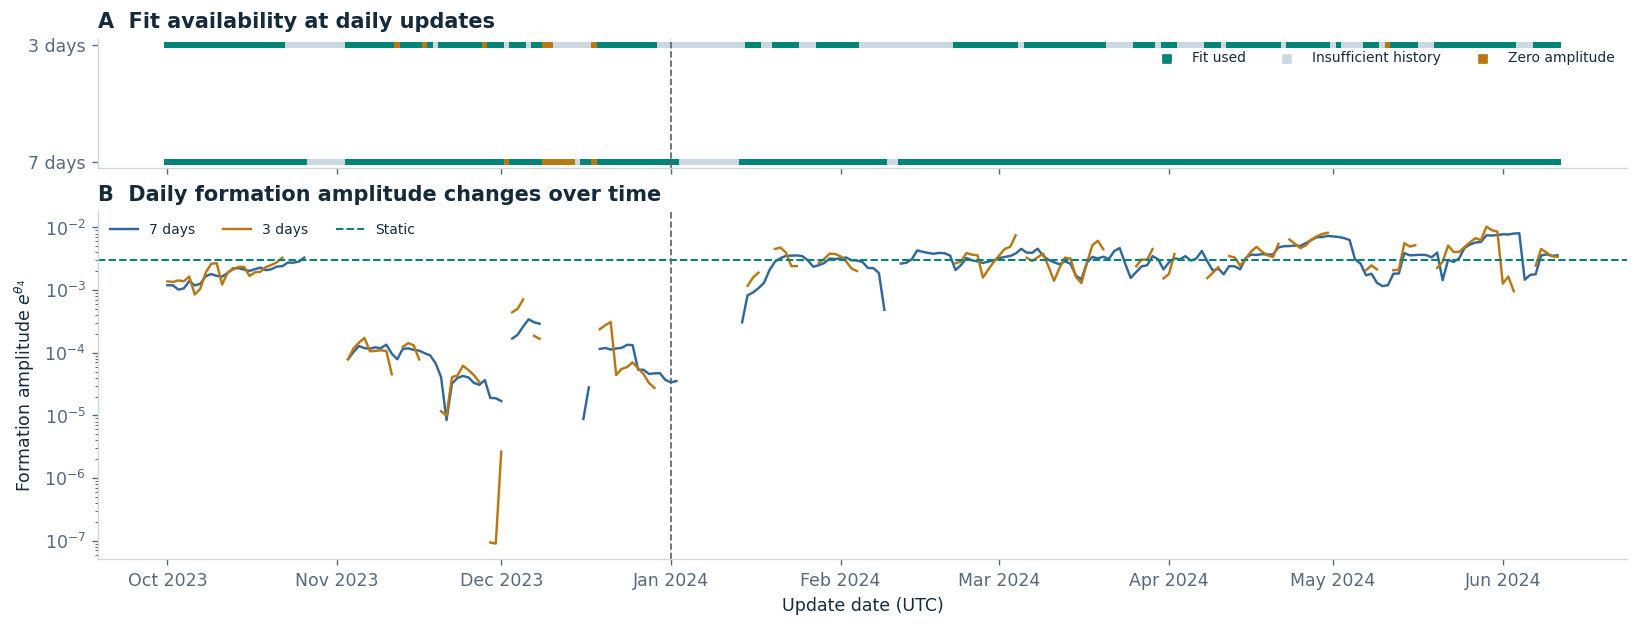

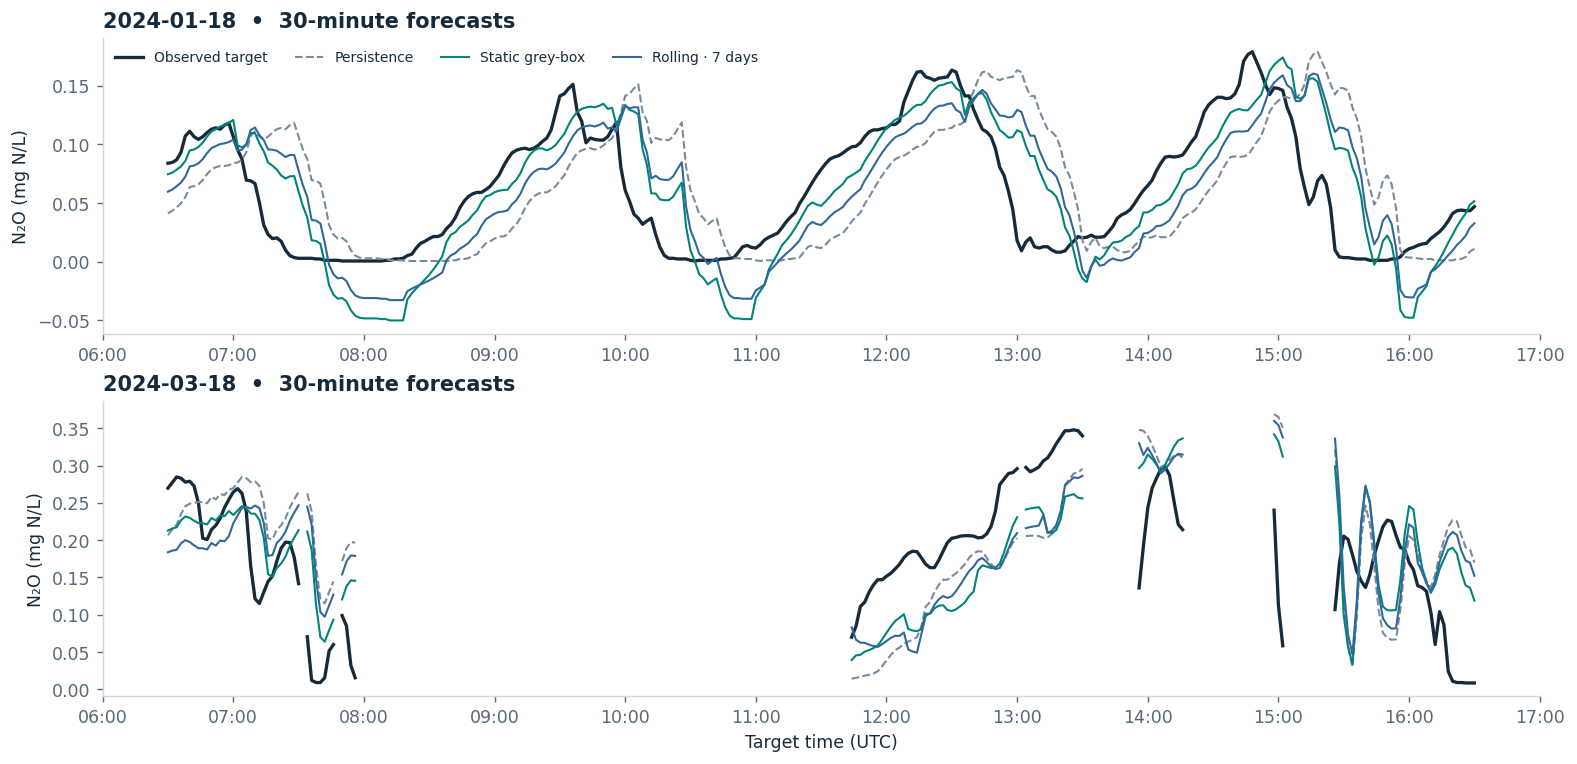

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(13, 4.9), sharex=True,
                         gridspec_kw={"height_ratios": [1, 2.7]})
status_colors = {
    "Fit used": TEAL, "Insufficient history": "#CBD7E1",
    "Zero amplitude": GOLD, "Fit failed": RUST,
}
for y, window_days in enumerate(WINDOWS):
    rows = schedule.loc[schedule["window_days"].eq(window_days)]
    axes[0].scatter(rows["update_time_utc"], np.repeat(y, len(rows)), s=12, marker="s",
                    c=rows["status"].map(status_colors), linewidths=0)
    axes[1].plot(rows["update_time_utc"], rows["amplitude"], lw=1.4,
                 label=f"{window_days} days", color=COLORS[f"Rolling · {window_days} days"])
axes[0].set_yticks(range(len(WINDOWS)), [f"{d} days" for d in WINDOWS])
axes[0].set_title("A  Fit availability at daily updates", loc="left")
for status in ("Fit used", "Insufficient history", "Zero amplitude"):
    axes[0].scatter([], [], c=status_colors[status], marker="s", label=status, s=24)
axes[0].legend(ncol=3, fontsize=8, loc="upper right")
axes[1].axhline(STATIC_AMPLITUDE, lw=1.15, ls="--", color=TEAL, label="Static")
axes[1].set(yscale="log", ylabel=r"Formation amplitude $e^{\theta_4}$", xlabel="Update date (UTC)")
axes[1].set_title("B  Daily formation amplitude changes over time", loc="left")
axes[1].legend(ncol=3, fontsize=8)
for ax in axes:
    ax.axvline(TEST_START, color=MUTED, ls="--", lw=1)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
show_figure(fig, "14_daily_update_history")

# Illustrate two fixed dates from the same test cohort.
fig, axes = plt.subplots(2, 1, figsize=(12.5, 6), sharey=False)
for ax, day in zip(axes, ["2024-01-18", "2024-03-18"]):
    start = pd.Timestamp(day, tz="UTC") + pd.Timedelta(hours=6)
    clock = pd.date_range(start, start + pd.Timedelta(hours=10), freq=STEP)
    pred = test_pred.reindex(clock)
    target_clock = clock + HORIZON * STEP
    ax.plot(target_clock, target_n2o.where(gb_ready).reindex(clock),
            color=INK, lw=1.9, label="Observed target")
    for name in ("Persistence", "Static grey-box", "Rolling · 7 days"):
        ax.plot(target_clock, pred[name], color=COLORS[name], lw=1.2,
                ls="--" if name == "Persistence" else "-", label=name)
    ax.set(ylabel="N₂O (mg N/L)")
    ax.set_title(f"{day}  •  30-minute forecasts", loc="left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[0].legend(ncol=4, fontsize=8, loc="upper left")
axes[1].set_xlabel("Target time (UTC)")
show_figure(fig, "15_test_forecast_examples")

### Matched comparison across model families

The archived baseline experiment and the grey-box experiment scored different sets of origins. The following supplementary comparison intersects the **replayed** baseline and grey-box test cohorts. It measures how the models compare where both families have the required inputs.

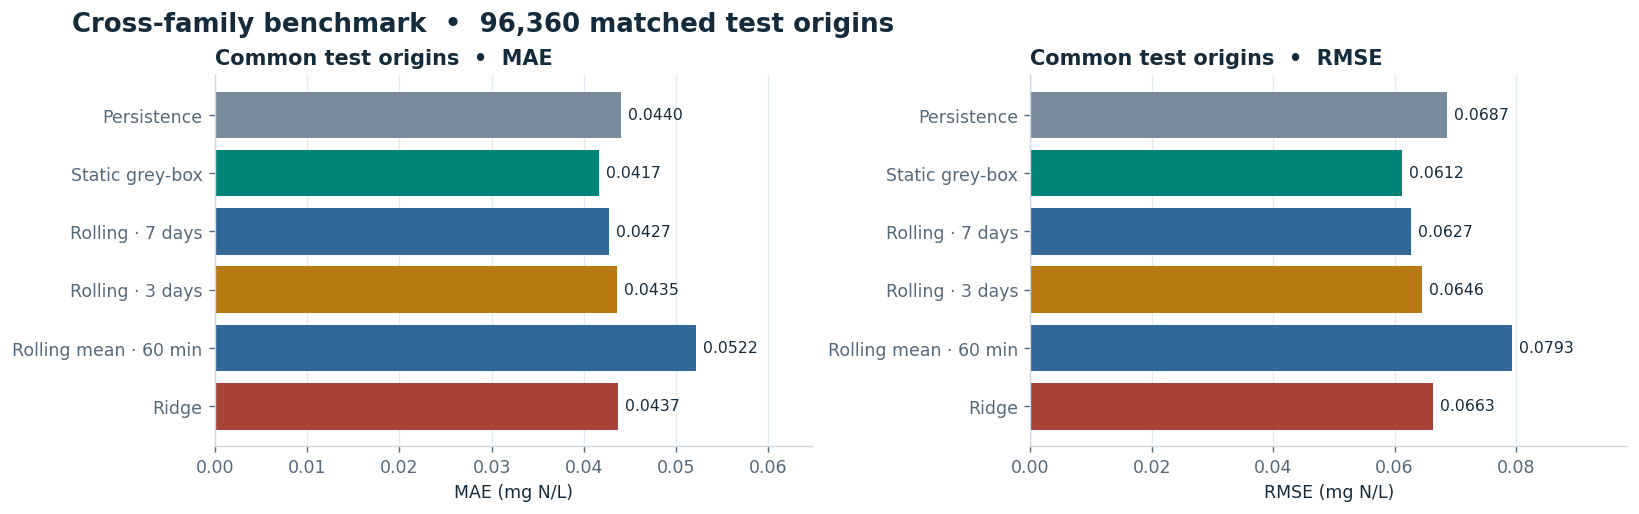

,n,MAE,RMSE,mean_error,MAE_improvement_pct,RMSE_improvement_pct
model,,,,,,
Persistence,96360,0.044035,0.068663,-0.000071,0.000000,0.000000
Static grey-box,96360,0.041683,0.061164,0.001732,5.342858,10.921817
Rolling · 7 days,96360,0.042676,0.062678,-0.000112,3.087863,8.716353
Rolling · 3 days,96360,0.043541,0.064560,0.000342,1.122874,5.975871
Rolling mean · 60 min,96360,0.052163,0.079283,0.000236,-18.456151,-15.466969
Ridge,96360,0.043737,0.066286,0.002783,0.678222,3.462299


In [18]:
common_test = test_pred.index.intersection(baseline_predictions["Test"].index)
matched = test_pred.loc[common_test].join(
    baseline_predictions["Test"].loc[common_test, ["Rolling mean · 60 min", "Ridge"]]
)
matched_metrics = scores(matched, target_n2o.loc[common_test])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    plot_score_bars(ax, matched_metrics, metric, f"Common test origins  •  {metric}")
fig.suptitle(f"Cross-family benchmark  •  {len(common_test):,} matched test origins",
             x=.04, ha="left", fontweight="bold", fontsize=15)
show_figure(fig, "16_matched_model_families")
display(matched_metrics.round(6))

## Conclusions and scope

- **Quality screening changes the usable sample.** Major N₂O and NH₄ gaps persisted after grid alignment. Source diagnostics separate intervals with rejected readings from intervals with no observations. Negative and repeated values are retained as properties of the observed sensor series.
- **Persistence is a demanding short-horizon reference.** In the original baseline analysis, the trailing mean with the best validation RMSE deteriorated on test, and Ridge exhibited positive validation bias.
- **The best delay depends on the forecast horizon.** NH₄ uses 24 minutes for the best one-step validation RMSE in the common delay screen. The 22-minute model performs best for the 30-minute validation rollout among the five retained candidates.
- **N₂O refitting helps selectively.** The seven-day window uses fitted parameters more often than the three-day window. It improves pooled test MAE and RMSE versus persistence on the grey-box cohort, while the static grey-box has the lowest pooled errors. March shows that update availability and forecast skill can move independently.

The target is measured concentration in one biological tank. These results describe forecast accuracy on eligible origins, and the NH₄ delay comparison is a validation result. Negative sensor readings and negative forecasts are retained in the reported errors. The N₂O test interval was reused from the original baseline notebook. The study scope is observational forecasting of the sensor record.

In [19]:
best_nh4 = nh4_rollout_scores.loc[nh4_delay_choice]
test = greybox_metrics.loc["Test"]
r7 = test.loc["Rolling · 7 days"]
static = test.loc["Static grey-box"]
display(Markdown(
    f"**Recomputed at this run.** The NH₄ {nh4_delay_choice} model reduced validation "
    f"MAE by **{best_nh4['MAE_improvement_pct']:.2f}%** and RMSE by "
    f"**{best_nh4['RMSE_improvement_pct']:.2f}%** on **{int(best_nh4['n']):,}** origins. "
    f"The N₂O test comparison covered **{int(r7['n']):,}** origins "
    f"(**{r7['coverage_pct']:.2f}%** coverage). The seven-day model reduced MAE by "
    f"**{r7['MAE_improvement_pct']:.2f}%** and RMSE by **{r7['RMSE_improvement_pct']:.2f}%** "
    f"versus persistence, with **{r7['fallback_pct']:.2f}%** fallback. "
    f"The static model's test MAE and RMSE were **{static['MAE']:.5f}** and "
    f"**{static['RMSE']:.5f} mg N/L**."
))

**Recomputed at this run.** The NH₄ 22 min model reduced validation MAE by **38.47%** and RMSE by **31.33%** on **50,224** origins. The N₂O test comparison covered **99,678** origins (**84.99%** coverage). The seven-day model reduced MAE by **2.29%** and RMSE by **8.05%** versus persistence, with **7.20%** fallback. The static model's test MAE and RMSE were **0.04181** and **0.06105 mg N/L**.

## Reusable outputs

The tables below retain the sample counts, error definitions and update provenance needed to reproduce the figures. The figures are saved as PNG files. Grey-box forecast rows include target timestamps and flags for whether a rolling fit was used.

In [20]:
tables = {
    "variable_dictionary": dictionary, "data_quality": audit, "gap_summary": gap_summary,
    "major_gap_sources": major_gaps, "monthly_coverage": coverage, "split_audit": split_audit,
    "historical_baselines": historical_baselines, "replayed_baselines": baseline_replay,
    "historical_monthly_baselines": historical_monthly_baselines,
    "nh4_initial_one_step": nh4_initial_scores, "nh4_delay_screen": nh4_delay,
    "nh4_validation_rollout": nh4_rollout_scores,
    "n2o_phase_summary": phase_summary, "n2o_delay_contrast": lag_contrast,
    "n2o_greybox_metrics": greybox_metrics, "n2o_monthly_test_metrics": test_monthly,
    "n2o_daily_update_schedule": schedule, "n2o_matched_test_metrics": matched_metrics,
}
for name, table in tables.items():
    table.to_csv(OUTPUT_DIR / f"{name}.csv")

forecast_export = test_pred.join(test_used.add_suffix(" used_fit"))
forecast_export.insert(0, "target_time_utc", forecast_export.index + HORIZON * STEP)
forecast_export.insert(1, "observed_N2O", target_n2o.loc[forecast_export.index])
forecast_export.to_csv(OUTPUT_DIR / "n2o_test_forecasts.csv.gz", index_label="forecast_time_utc")
data.to_csv(OUTPUT_DIR / "model_variables_2min.csv.gz", index_label="time")
flags.to_csv(OUTPUT_DIR / "diagnostic_flags_2min.csv.gz", index_label="time")
alignment_metadata.to_csv(OUTPUT_DIR / "alignment_metadata_2min.csv.gz", index_label="time")
protocol = {
    "source_file": source_path.name, "source_sha256": source_sha256,
    "grid_minutes": int(STEP / pd.Timedelta(minutes=1)), "forecast_horizon_bins": HORIZON,
    "validation_start_utc": VALIDATION_START.isoformat(), "test_start_utc": TEST_START.isoformat(),
    "nh4_delay_minutes": 2 * nh4_choice_steps, "n2o_delay_minutes": 2 * N2O_DELAY_STEPS,
    "theta1": float(theta1), "theta2": float(theta2), "theta3": THETA3,
    "theta4_static": THETA4, "theta5": float(theta5),
    "theta6_static": float(theta6), "theta7_static": float(theta7),
    "primary_window_days": WINDOWS[0], "comparison_window_days": WINDOWS[1],
    "daily_update_hour_utc": 0, "minimum_phases_per_mode": MIN_PHASES,
    "minimum_denit_steps_per_inlet_state": MIN_DN_STEPS,
    "rolling_loss": "soft_l1", "amplitude_scale_quantile": .95,
    "amplitude_scale_floor": 1e-6, "future_inputs": "hold_at_origin",
    "fallback": "persistence",
}
(OUTPUT_DIR / "protocol.json").write_text(json.dumps(protocol, indent=2) + "\n", encoding="utf-8")
print(f"Saved {len(list(FIGURE_DIR.glob('*.png')))} figures and "
      f"{sum(path.is_file() for path in OUTPUT_DIR.iterdir())} data and protocol files.")

Saved 16 figures and 23 data and protocol files.
